# Understanding the Data, Generating New Features, and Implementing the Screen

In [1]:
# Cell 1
# Import Libraries and examine the contents of the database
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Create a small database to test code (equities_class.db), since the larger database may take a while. 
USE_SMALL_DB = True

# I placed copies of the equities_class.duckdb and equities_top2000.duckdb inside my valerie_macisaac folder
DATA_DIR = Path(".") 
DB_PATH = DATA_DIR / ("equities_class.duckdb" if USE_SMALL_DB else "equities_top2000.duckdb")

# Check to make sure the path exists
assert DB_PATH.exists(), f"Database not found at {DB_PATH.resolve()}"
con = duckdb.connect(str(DB_PATH), read_only=True)

# Inspect tables so I know what information we have and can use to generate features. 
tables = con.execute("SHOW TABLES").df()
print("Tables in database:", tables['name'].tolist())

# For each table, inspect the column names
for table_name in tables['name']:
    print(f"\n{'='*40}\nTable: {table_name}\n{'='*40}")
    schema = con.execute(f"DESCRIBE {table_name}").df()
    print(schema[['column_name', 'column_type']])
    display(con.execute(f"SELECT * FROM {table_name} LIMIT 3").df())

Tables in database: ['benchmark', 'calendar', 'dataset_metadata', 'dividends', 'fundamentals', 'prices', 'universe', 'universe_candidates', 'universe_membership', 'universe_rebalances']

Table: benchmark
  column_name column_type
0      symbol     VARCHAR
1        date        DATE
2       close      DOUBLE
3   adj_close      DOUBLE
4      source     VARCHAR


,symbol,date,close,adj_close,source
0,^SP500TR,2008-01-02,2273.41,2273.41,fmp
1,^SP500TR,2008-01-03,2273.41,2273.41,fmp
2,^SP500TR,2008-01-04,2217.59,2217.59,fmp



Table: calendar
  column_name column_type
0        date        DATE


,date
0,2008-01-02
1,2008-01-03
2,2008-01-04



Table: dataset_metadata
  column_name column_type
0         key     VARCHAR
1       value     VARCHAR


,key,value
0,history_end,2015-12-31
1,benchmark,^SP500TR
2,price_start,2008-01-01


... (10 outputs left out)


Table: universe_membership
              column_name column_type
0           quarter_start        DATE
1             quarter_end        DATE
2          selection_date        DATE
3         effective_start        DATE
4                  symbol     VARCHAR
5         selection_close      DOUBLE
6      shares_fiscal_date        DATE
7      shares_filing_date        DATE
8   shares_available_date        DATE
9        selection_shares      DOUBLE
10       market_cap_proxy      DOUBLE
11          universe_rank      BIGINT


,quarter_start,quarter_end,selection_date,effective_start,symbol,selection_close,shares_fiscal_date,shares_filing_date,shares_available_date,selection_shares,market_cap_proxy,universe_rank
0,2008-01-01,2008-03-31,2007-12-31,2008-01-02,XOM,93.69,2007-09-30,2007-11-07,2007-11-08,5.535294e+09,5.186017e+11,1
1,2008-01-01,2008-03-31,2007-12-31,2008-01-02,POZN,12.00,2007-09-30,2007-11-05,2007-11-06,2.955579e+10,3.546694e+11,3
2,2008-01-01,2008-03-31,2007-12-31,2008-01-02,MSFT,35.60,2007-09-30,2007-10-25,2007-10-26,9.513000e+09,3.386628e+11,4



Table: universe_rebalances
                   column_name column_type
0                quarter_start        DATE
1                  quarter_end        DATE
2               selection_date        DATE
3              effective_start        DATE
4    positive_quote_candidates      BIGINT
5          rankable_candidates      BIGINT
6               selected_count      BIGINT
7                    shortfall      BIGINT
8  selected_currently_inactive      BIGINT
9            delivered_members      BIGINT


,quarter_start,quarter_end,selection_date,effective_start,positive_quote_candidates,rankable_candidates,selected_count,shortfall,selected_currently_inactive,delivered_members
0,2008-01-01,2008-03-31,2007-12-31,2008-01-02,2048,1821,1821,179,492,30
1,2008-04-01,2008-06-30,2008-03-31,2008-04-01,2063,1833,1833,167,494,30
2,2008-07-01,2008-09-30,2008-06-30,2008-07-01,2076,1849,1849,151,501,30


In [2]:
# Cell 2
# If a trading decision is made on day t, it excecutes on day t+1 (LEAD (date, 1)
# The exit dates are 90 days after the entry date
# Left join if 90 days later is not a trading day, rounds up to the next open trading session
# calendar generates a mapping of signal_date, entry_date, maturity_calendar_date, and exit_date

calendar_query = """
WITH trading_days AS (
    SELECT 
        date AS signal_date,
        LEAD(date, 1) OVER (ORDER BY date) AS entry_date
    FROM calendar
)
SELECT 
    t.signal_date,
    t.entry_date,
    t.entry_date + INTERVAL 90 DAY AS maturity_calendar_date,
    MIN(c_exit.date) AS exit_date
FROM trading_days t
LEFT JOIN calendar c_exit 
    ON c_exit.date >= t.entry_date + INTERVAL 90 DAY
WHERE t.entry_date IS NOT NULL
GROUP BY t.signal_date, t.entry_date
ORDER BY t.signal_date
"""

schedule_df = con.execute(calendar_query).df()
print(f"Total trading days mapped: {len(schedule_df)}")
display(schedule_df.head(5))
display(schedule_df.tail(5))

Total trading days mapped: 2014


,signal_date,entry_date,maturity_calendar_date,exit_date
0,2008-01-02,2008-01-03,2008-04-02,2008-04-02
1,2008-01-03,2008-01-04,2008-04-03,2008-04-03
2,2008-01-04,2008-01-07,2008-04-06,2008-04-07
3,2008-01-07,2008-01-08,2008-04-07,2008-04-07
4,2008-01-08,2008-01-09,2008-04-08,2008-04-08


,signal_date,entry_date,maturity_calendar_date,exit_date
2009,2015-12-23,2015-12-24,2016-03-23,NaT
2010,2015-12-24,2015-12-28,2016-03-27,NaT
2011,2015-12-28,2015-12-29,2016-03-28,NaT
2012,2015-12-29,2015-12-30,2016-03-29,NaT
2013,2015-12-30,2015-12-31,2016-03-30,NaT


In [3]:
# Cell 3
# Quick check on the period types (whether quarterly or annual), check for filing lag in days
# Output shows that all fundamentals have period type quarter, that they all have a filing date,
# and that there is an average lag of 40 days when filing. 
print("Fundamentals period types:")
display(con.execute("""
    SELECT period, COUNT(*) as n_rows, 
           COUNT(filing_date) as n_with_filing_date,
           AVG(filing_date - fiscal_date) as avg_filing_lag_days
    FROM fundamentals 
    GROUP BY period
""").df())

# Visualize quarter_start vs effective_start to visualize the lag, inspecting which stocks can
# actually be traded. In the output, in Q1, Q2, Q3, 30 stocks traded, but in Q4 only 29 traded
print("\nUniverse membership counts per quarter (first 5):")
display(con.execute("""
    SELECT quarter_start, effective_start, quarter_end, COUNT(DISTINCT symbol) as n_stocks
    FROM universe_membership
    GROUP BY 1, 2, 3
    ORDER BY 1
    LIMIT 5
""").df())

Fundamentals period types:


,period,n_rows,n_with_filing_date,avg_filing_lag_days
0,quarter,1059,1059,40.270066



Universe membership counts per quarter (first 5):


,quarter_start,effective_start,quarter_end,n_stocks
0,2008-01-01,2008-01-02,2008-03-31,30
1,2008-04-01,2008-04-01,2008-06-30,30
2,2008-07-01,2008-07-01,2008-09-30,30
3,2008-10-01,2008-10-01,2008-12-31,29
4,2009-01-01,2009-01-02,2009-03-31,30


In [4]:
# Cell 4
# Check whether the signal, entry, and exit prices are available for every stock on every day
coverage_query = """
WITH trading_days AS (
    SELECT 
        date AS signal_date,
        LEAD(date, 1) OVER (ORDER BY date) AS entry_date
    FROM calendar
),
schedule AS (
    SELECT 
        t.signal_date,
        t.entry_date,
        MIN(c_exit.date) AS exit_date
    FROM trading_days t
    LEFT JOIN calendar c_exit 
        ON c_exit.date >= t.entry_date + INTERVAL 90 DAY
    WHERE t.entry_date IS NOT NULL
    GROUP BY t.signal_date, t.entry_date
)
SELECT 
     COUNT(*) AS total_candidate_days,
    COUNT(p_sig.adj_close) AS has_signal_price,
    COUNT(p_ent.adj_close) AS has_entry_price,
    COUNT(p_ext.adj_close) AS has_exact_exit_price,
    SUM(CASE WHEN s.exit_date IS NOT NULL AND p_ext.adj_close IS NULL THEN 1 ELSE 0 END) AS missing_exit_when_calendar_exists
FROM schedule s
JOIN universe_membership um
    ON s.signal_date BETWEEN um.effective_start AND um.quarter_end
LEFT JOIN prices p_sig 
    ON p_sig.symbol = um.symbol AND p_sig.date = s.signal_date
LEFT JOIN prices p_ent 
    ON p_ent.symbol = um.symbol AND p_ent.date = s.entry_date
LEFT JOIN prices p_ext 
    ON p_ext.symbol = um.symbol AND p_ext.date = s.exit_date
WHERE s.signal_date >= '2010-01-01'
"""
display(con.execute(coverage_query).df())

# Output shows that on the 44010 candidate days, there are 43665 days with an signal price. This implies that 
# when building the backtester, there has to be a plan for stocks that dont trade on day 90. For example, 
# we can add a data screen to ensure the stocks chosen to trade with are relatively stable in being present
# in the database, or close the trades with the last known close price. 

,total_candidate_days,has_signal_price,has_entry_price,has_exact_exit_price,missing_exit_when_calendar_exists
0,44010,43665,43664,41975,299.0


In [5]:
# Cell 5
# Build the large table that combines the features from many of the earlier tables
# Will include: calendar info (signal_date, entry_date...), price features (daily_returns...)
# fundamental data (fund_clean...) (using ASOF to ensure that the fundamental data is actually data we 
# could access on day t), and calculates the forward return on the 90 day period

# Added some features such as ret_1d, ret_5d, ret_21d, ret_63d, ret_126d, ret_252d, vol_21d, vol_63d, 
# dollar_vol_21d, gross_margin (gross_profit / revenue), op_margin (operating_income / revenue), roa (net_income / total_assets)
# roe (net_income / total_equity), fcf_to_assets (free_cash_flow / total_assets), debt_to_assets (total_debt / total_assets),
# cash_to_assets (cash_and_equivalents / total_assets), earnings_yield (net_income / (close * shares_outstanding)), 
# book_to_market (total_equity / (close * shares_outstanding)), and target_90d_ret (exit_adj_close / entry_adj_close - 1.0)
panel_query = """
WITH trading_days AS (
    SELECT 
        date AS signal_date,
        LEAD(date, 1) OVER (ORDER BY date) AS entry_date
    FROM calendar
),
schedule AS (
    SELECT 
        t.signal_date,
        t.entry_date,
        MIN(c_exit.date) AS exit_date
    FROM trading_days t
    LEFT JOIN calendar c_exit 
        ON c_exit.date >= t.entry_date + INTERVAL 90 DAY
    WHERE t.entry_date IS NOT NULL
    GROUP BY t.signal_date, t.entry_date
),
daily_returns AS (
    SELECT 
        symbol,
        date,
        close,
        adj_close,
        volume,
        adj_close / LAG(adj_close, 1) OVER w - 1.0 AS ret_1d,
        adj_close / LAG(adj_close, 5) OVER w - 1.0 AS ret_5d,
        adj_close / LAG(adj_close, 21) OVER w - 1.0 AS ret_21d,
        adj_close / LAG(adj_close, 63) OVER w - 1.0 AS ret_63d,
        adj_close / LAG(adj_close, 126) OVER w - 1.0 AS ret_126d,
        adj_close / LAG(adj_close, 252) OVER w - 1.0 AS ret_252d
    FROM prices
    WINDOW w AS (PARTITION BY symbol ORDER BY date)
),
price_features AS (
    SELECT 
        symbol,
        date AS signal_date,
        close,
        adj_close,
        volume,
        ret_1d,
        ret_5d,
        ret_21d,
        ret_63d,
        ret_126d,
        ret_252d,
        STDDEV_SAMP(ret_1d) OVER (
            PARTITION BY symbol ORDER BY date ROWS BETWEEN 20 PRECEDING AND CURRENT ROW
        ) AS vol_21d,
        STDDEV_SAMP(ret_1d) OVER (
            PARTITION BY symbol ORDER BY date ROWS BETWEEN 62 PRECEDING AND CURRENT ROW
        ) AS vol_63d,
        AVG(close * volume) OVER (
            PARTITION BY symbol ORDER BY date ROWS BETWEEN 20 PRECEDING AND CURRENT ROW
        ) AS dollar_vol_21d
    FROM daily_returns
),
fund_clean AS (
    SELECT 
        symbol,
        filing_date,
        filing_date + INTERVAL 1 DAY AS available_date,
        fiscal_date,
        revenue,
        gross_profit,
        operating_income,
        net_income,
        ebitda,
        operating_cash_flow,
        free_cash_flow,
        total_assets,
        total_debt,
        total_equity,
        cash_and_equivalents,
        shares_outstanding
    FROM fundamentals
    WHERE filing_date IS NOT NULL
)
SELECT 
    s.signal_date,
    s.entry_date,
    s.exit_date,
    um.symbol,
    u.sector,
    um.universe_rank,
    um.market_cap_proxy,
    -- Price & Technical features on signal_date
    pf.close AS signal_close,
    pf.adj_close AS signal_adj_close,
    pf.ret_1d,
    pf.ret_5d,
    pf.ret_21d,
    pf.ret_63d,
    pf.ret_126d,
    pf.ret_252d,
    pf.vol_21d,
    pf.vol_63d,
    pf.dollar_vol_21d,
    -- Point-in-time Fundamental ratios (available_date <= signal_date)
    f.fiscal_date AS latest_fiscal_date,
    f.filing_date AS latest_filing_date,
    f.gross_profit / NULLIF(f.revenue, 0) AS gross_margin,
    f.operating_income / NULLIF(f.revenue, 0) AS op_margin,
    f.net_income / NULLIF(f.total_assets, 0) AS roa,
    f.net_income / NULLIF(f.total_equity, 0) AS roe,
    f.free_cash_flow / NULLIF(f.total_assets, 0) AS fcf_to_assets,
    f.total_debt / NULLIF(f.total_assets, 0) AS debt_to_assets,
    f.cash_and_equivalents / NULLIF(f.total_assets, 0) AS cash_to_assets,
    f.net_income / NULLIF(pf.close * f.shares_outstanding, 0) AS earnings_yield,
    f.total_equity / NULLIF(pf.close * f.shares_outstanding, 0) AS book_to_market,
    -- Execution prices & 90-calendar-day forward target return
    p_ent.adj_close AS entry_adj_close,
    p_ext.adj_close AS exit_adj_close,
    (p_ext.adj_close / NULLIF(p_ent.adj_close, 0)) - 1.0 AS target_90d_ret
FROM schedule s
JOIN universe_membership um
    ON s.signal_date BETWEEN um.effective_start AND um.quarter_end
LEFT JOIN universe u
    ON u.symbol = um.symbol
LEFT JOIN price_features pf
    ON pf.symbol = um.symbol AND pf.signal_date = s.signal_date
ASOF LEFT JOIN fund_clean f
    ON f.symbol = um.symbol AND f.available_date <= s.signal_date
LEFT JOIN prices p_ent
    ON p_ent.symbol = um.symbol AND p_ent.date = s.entry_date
LEFT JOIN prices p_ext
    ON p_ext.symbol = um.symbol AND p_ext.date = s.exit_date
WHERE s.signal_date >= '2010-01-01'
ORDER BY s.signal_date, um.symbol
"""

panel_df = con.execute(panel_query).df()
print(f"Panel shape: {panel_df.shape}")
display(panel_df.head(5))

# Note examples like row 2 (APDN) where the signal_close of 2.43 mil is artificially inflated by reverse-stock splits,
# we will need to create a screening metric in the backtester to avoid buying stocks like this. 

Panel shape: (44010, 32)


,signal_date,entry_date,exit_date,symbol,sector,universe_rank,market_cap_proxy,signal_close,signal_adj_close,ret_1d,...,roa,roe,fcf_to_assets,debt_to_assets,cash_to_assets,earnings_yield,book_to_market,entry_adj_close,exit_adj_close,target_90d_ret
0,2010-01-04,2010-01-05,2010-04-05,AAPL,Technology,9,1.927866e+11,7.64,6.40,0.014263,...,0.035052,0.052623,0.055536,0.000000,0.110798,0.008512,0.161756,6.42,7.14,0.112150
1,2010-01-04,2010-01-05,2010-04-05,AMT,Real Estate,135,1.753151e+10,43.46,33.18,0.005759,...,0.008023,0.020841,0.020427,0.498731,0.027359,0.003820,0.183283,33.73,33.08,-0.019271
2,2010-01-04,2010-01-05,2010-04-05,APDN,Healthcare,2,3.353045e+11,2430000.30,2430000.30,0.088710,...,-0.959764,0.828031,-0.419400,1.599402,0.141538,-0.000004,-0.000005,2520000.15,2520000.15,0.000000
3,2010-01-04,2010-01-05,2010-04-05,BESS,Utilities,88,2.741424e+10,168.00,168.00,0.000000,...,0.266119,-0.199431,-0.240560,0.023747,0.001966,0.000004,-0.000022,168.00,119.00,-0.291667
4,2010-01-04,2010-01-05,2010-04-05,BKNG,Consumer Cyclical,6,2.712106e+11,223.96,222.36,0.025409,...,0.177505,0.265437,0.107617,0.150769,0.201706,0.001147,0.004321,224.94,255.81,0.137237


In [6]:
# Cell 6
# Explore the missing trading dates visualized earlier
missing_check = con.execute("""
WITH last_price_per_stock AS (
    SELECT symbol, MIN(date) AS first_price_date, MAX(date) AS last_price_date, COUNT(*) AS n_price_days
    FROM prices
    GROUP BY symbol
)
SELECT 
    um.symbol,
    u.name,
    u.is_active_snapshot,
    u.delisted_at_snapshot,
    MIN(um.quarter_start) AS first_um_qtr,
    MAX(um.quarter_end) AS last_um_qtr,
    lp.first_price_date,
    lp.last_price_date,
    lp.n_price_days
FROM (SELECT DISTINCT symbol, quarter_start, quarter_end FROM universe_membership) um
LEFT JOIN universe u ON u.symbol = um.symbol
LEFT JOIN last_price_per_stock lp ON lp.symbol = um.symbol
GROUP BY 1, 2, 3, 4, 7, 8, 9
ORDER BY lp.last_price_date NULLS FIRST
""").df()

display(missing_check)
# Based on the results, it is clear that CCZ only traded 851 out of the 2015 days. This implies that if the backtester were to try to sell,
# it would be unable to complete the sell at 90 days. Therefore, we will make a screen to ensure we only trade stocks that were active the
# last 63 trading days (last quarter). 

,symbol,name,is_active_snapshot,delisted_at_snapshot,first_um_qtr,last_um_qtr,first_price_date,last_price_date,n_price_days
0,CCZ,Comcast Holdings Corp.,1,NaT,2008-01-01,2015-12-31,2008-01-02,2015-12-22,851
1,XOM,Exxonmobil Holdings Corporation,1,NaT,2008-01-01,2015-12-31,2008-01-02,2015-12-31,2015
2,FCX,Freeport-McMoRan Inc.,1,NaT,2008-01-01,2015-12-31,2008-01-02,2015-12-31,2015
3,AMT,American Tower Corporation,1,NaT,2008-01-01,2015-12-31,2008-01-02,2015-12-31,2015
4,SPG,"Simon Property Group, Inc.",1,NaT,2008-01-01,2015-12-31,2008-01-02,2015-12-31,2015
5,POZN,POZEN Inc.,0,NaT,2008-01-01,2015-09-30,2008-01-02,2015-12-31,2015
6,PG,The Procter & Gamble Company,1,NaT,2008-01-01,2015-12-31,2008-01-02,2015-12-31,2015
7,BKNG,Booking Holdings Inc.,1,NaT,2008-01-01,2015-12-31,2008-01-02,2015-12-31,2015
8,JNJ,Johnson & Johnson,1,NaT,2008-01-01,2015-12-31,2008-01-02,2015-12-31,2015
9,KO,The Coca-Cola Company,1,NaT,2008-01-01,2015-12-31,2008-01-02,2015-12-31,2015


In [7]:
# Cell 7
# Implement the screening mentioned in the earlier cells based on the anomalies/problems detected. 
# i.e. eliminate issue-ridden, non-tradeable stocks from model training. 
# The screen checks that the stock traded the last 62 days (it does this by checking the date 62 sessions ago on the calendar 
# and then checking if it matches the date this stock traded at 62 price rows ago), checks that the volume traded over the last 
# month is nonzero, the average volume traded within last month is at least 1mil a day (to ensure liquidity), and that 
# the market cap is inbetween 1% and 5000% of its assets.
# 
# I added more features (suggested by Gemini): mom_6m_skip1m: 6-month momentum skipping the most recent 1 month, 
# mom_12m_skip1m: 12-month momentum, hl_spread & avg_hl_spread_21d, sharpe_63d, ebitda_to_assets (ebitda / total_assets)
# ocf_to_assets (operating_cash_flow / total_assets), fcf_yield (free_cash_flow / market_cap_proxy), 
# has_full_63d_trading: Boolean check of screening explained above, min_vol_21d (21-day minimum volume to trading stopping)
# mcap_to_assets_sanity: Ratio of market_cap_proxy / total_assets, and adjusted earnings_yield and book_to_market to use the 
# point-in-time market_cap_proxy 

panel_query_v2 = """
WITH trading_days AS (
    SELECT 
        date AS signal_date,
        LEAD(date, 1) OVER (ORDER BY date) AS entry_date,
        LAG(date, 62) OVER (ORDER BY date) AS date_minus_62d
    FROM calendar
),
schedule AS (
    SELECT 
        t.signal_date,
        t.entry_date,
        t.date_minus_62d,
        MIN(c_exit.date) AS exit_date
    FROM trading_days t
    LEFT JOIN calendar c_exit 
        ON c_exit.date >= t.entry_date + INTERVAL 90 DAY
    WHERE t.entry_date IS NOT NULL
    GROUP BY t.signal_date, t.entry_date, t.date_minus_62d
),
daily_returns AS (
    SELECT 
        symbol,
        date,
        open,
        high,
        low,
        close,
        adj_close,
        volume,
        LAG(date, 62) OVER w AS stock_date_minus_62d,
        adj_close / NULLIF(LAG(adj_close, 1) OVER w, 0) - 1.0 AS ret_1d,
        adj_close / NULLIF(LAG(adj_close, 5) OVER w, 0) - 1.0 AS ret_5d,
        adj_close / NULLIF(LAG(adj_close, 21) OVER w, 0) - 1.0 AS ret_21d,
        adj_close / NULLIF(LAG(adj_close, 63) OVER w, 0) - 1.0 AS ret_63d,
        adj_close / NULLIF(LAG(adj_close, 126) OVER w, 0) - 1.0 AS ret_126d,
        adj_close / NULLIF(LAG(adj_close, 252) OVER w, 0) - 1.0 AS ret_252d,
        (high - low) / NULLIF(close, 0) AS hl_spread
    FROM prices
    WINDOW w AS (PARTITION BY symbol ORDER BY date)
),
price_features AS (
    SELECT 
        symbol,
        date AS signal_date,
        close,
        adj_close,
        volume,
        stock_date_minus_62d,
        ret_1d,
        ret_5d,
        ret_21d,
        ret_63d,
        ret_126d,
        ret_252d,
        -- Momentum skipping most recent month (classic 6m-1m and 12m-1m momentum)
        (1.0 + ret_126d) / NULLIF(1.0 + ret_21d, 0) - 1.0 AS mom_6m_skip1m,
        (1.0 + ret_252d) / NULLIF(1.0 + ret_21d, 0) - 1.0 AS mom_12m_skip1m,
        STDDEV_SAMP(ret_1d) OVER w21 AS vol_21d,
        STDDEV_SAMP(ret_1d) OVER w63 AS vol_63d,
        AVG(hl_spread) OVER w21 AS avg_hl_spread_21d,
        AVG(close * volume) OVER w21 AS dollar_vol_21d,
        MIN(volume) OVER w21 AS min_vol_21d
    FROM daily_returns
    WINDOW 
        w21 AS (PARTITION BY symbol ORDER BY date ROWS BETWEEN 20 PRECEDING AND CURRENT ROW),
        w63 AS (PARTITION BY symbol ORDER BY date ROWS BETWEEN 62 PRECEDING AND CURRENT ROW)
),
fund_clean AS (
    SELECT 
        symbol,
        filing_date,
        filing_date + INTERVAL 1 DAY AS available_date,
        fiscal_date,
        revenue,
        gross_profit,
        operating_income,
        net_income,
        ebitda,
        operating_cash_flow,
        free_cash_flow,
        total_assets,
        total_debt,
        total_equity,
        cash_and_equivalents,
        shares_outstanding
    FROM fundamentals
    WHERE filing_date IS NOT NULL
)
SELECT 
    s.signal_date,
    s.entry_date,
    s.exit_date,
    um.symbol,
    u.sector,
    um.universe_rank,
    um.market_cap_proxy,
    pf.close AS signal_close,
    pf.adj_close AS signal_adj_close,
    -- Tradability screen flags (100% point-in-time as of signal_date)
    (pf.stock_date_minus_62d = s.date_minus_62d) AS has_full_63d_trading,
    pf.min_vol_21d,
    pf.dollar_vol_21d,
    um.market_cap_proxy / NULLIF(f.total_assets, 0) AS mcap_to_assets_sanity,
    -- Technical Features
    pf.ret_1d,
    pf.ret_5d,
    pf.ret_21d,
    pf.ret_63d,
    pf.ret_126d,
    pf.ret_252d,
    pf.mom_6m_skip1m,
    pf.mom_12m_skip1m,
    pf.vol_21d,
    pf.vol_63d,
    pf.avg_hl_spread_21d,
    pf.ret_63d / NULLIF(pf.vol_63d, 0) AS sharpe_63d,
    -- Fundamental Features (Point-in-Time ASOF join)
    f.gross_profit / NULLIF(f.revenue, 0) AS gross_margin,
    f.operating_income / NULLIF(f.revenue, 0) AS op_margin,
    f.net_income / NULLIF(f.total_assets, 0) AS roa,
    f.operating_cash_flow / NULLIF(f.total_assets, 0) AS ocf_to_assets,
    f.free_cash_flow / NULLIF(f.total_assets, 0) AS fcf_to_assets,
    f.ebitda / NULLIF(f.total_assets, 0) AS ebitda_to_assets,
    f.total_debt / NULLIF(f.total_assets, 0) AS debt_to_assets,
    f.cash_and_equivalents / NULLIF(f.total_assets, 0) AS cash_to_assets,
    f.net_income / NULLIF(um.market_cap_proxy, 0) AS earnings_yield,
    f.free_cash_flow / NULLIF(um.market_cap_proxy, 0) AS fcf_yield,
    f.total_equity / NULLIF(um.market_cap_proxy, 0) AS book_to_market,
    -- Execution Prices & Forward 90-Calendar-Day Return
    p_ent.adj_close AS entry_adj_close,
    p_ext.adj_close AS exit_adj_close,
    (p_ext.adj_close / NULLIF(p_ent.adj_close, 0)) - 1.0 AS target_90d_ret
FROM schedule s
JOIN universe_membership um
    ON s.signal_date BETWEEN um.effective_start AND um.quarter_end
LEFT JOIN universe u
    ON u.symbol = um.symbol
LEFT JOIN price_features pf
    ON pf.symbol = um.symbol AND pf.signal_date = s.signal_date
ASOF LEFT JOIN fund_clean f
    ON f.symbol = um.symbol AND f.available_date <= s.signal_date
LEFT JOIN prices p_ent
    ON p_ent.symbol = um.symbol AND p_ent.date = s.entry_date
LEFT JOIN prices p_ext
    ON p_ext.symbol = um.symbol AND p_ext.date = s.exit_date
WHERE s.signal_date >= '2010-01-01'
ORDER BY s.signal_date, um.symbol
"""

panel_df = con.execute(panel_query_v2).df()

# Apply screening
screen_mask = (
    (panel_df['has_full_63d_trading'] == True) &
    (panel_df['min_vol_21d'] > 0) &
    (panel_df['dollar_vol_21d'] >= 1_000_000) &
    (panel_df['mcap_to_assets_sanity'].between(0.01, 50.0))
)

screened_df = panel_df[screen_mask].copy()
print(f"Raw candidate-days: {len(panel_df):,} | Screened candidate-days: {len(screened_df):,}")
print("Symbols remaining after point-in-time screen:", sorted(screened_df['symbol'].unique()))
print("Symbols filtered out:", sorted(set(panel_df['symbol'].unique()) - set(screened_df['symbol'].unique())))
print("Missing exit prices after screen (when exit_date is in calendar):", 
      screened_df[screened_df['exit_date'].notna()]['exit_adj_close'].isna().sum())

Raw candidate-days: 44,010 | Screened candidate-days: 35,849
Symbols remaining after point-in-time screen: ['AAPL', 'AMT', 'BRK-A', 'BRK-B', 'CVX', 'ETR', 'FCX', 'GE', 'IBM', 'JNJ', 'JPM', 'KO', 'MCD', 'MMM', 'MSFT', 'ORLY', 'PG', 'POZN', 'SCCO', 'SPG', 'T', 'TSYS', 'UPS', 'WMT', 'XOM']
Symbols filtered out: ['APDN', 'BESS', 'BKNG', 'CCZ', 'PEGY']
Missing exit prices after screen (when exit_date is in calendar): 0


In [8]:
# Cell 8
# Make an aggregated table to check that the screening is accurate
diag_df = panel_df.groupby('symbol').agg(
    n_days=('signal_date', 'count'),
    pct_full_63d=('has_full_63d_trading', 'mean'),
    min_close=('signal_close', 'min'),
    median_close=('signal_close', 'median'),
    max_close=('signal_close', 'max'),
    median_dollar_vol=('dollar_vol_21d', 'median'),
    median_mcap_proxy=('market_cap_proxy', 'median'),
    median_mcap_to_assets=('mcap_to_assets_sanity', 'median')
).reset_index()

display(diag_df.sort_values('median_mcap_to_assets', ascending=False))

,symbol,n_days,pct_full_63d,min_close,median_close,max_close,median_dollar_vol,median_mcap_proxy,median_mcap_to_assets
2,APDN,1509,1.0,1.080000e+06,2.520000e+06,1.036800e+07,0.000000e+00,2.405113e+11,174825.495627
20,PEGY,1509,1.0,2.244000e+04,3.411000e+04,6.180003e+04,1.499357e+05,2.894346e+11,2725.196389
3,BESS,1509,1.0,2.940000e+01,8.120000e+01,2.660000e+02,9.304067e+03,1.519951e+10,2573.402457
4,BKNG,1509,1.0,1.751900e+02,6.941000e+02,1.469560e+03,6.312582e+08,8.815502e+11,146.038005
19,ORLY,1509,1.0,3.773000e+01,9.735000e+01,2.762600e+02,9.221020e+07,1.701785e+11,29.399013
23,SCCO,1509,1.0,2.336000e+01,3.019000e+01,4.829000e+01,6.505973e+07,2.492204e+10,2.901603
0,AAPL,1509,1.0,6.860000e+00,1.854000e+01,3.325000e+01,6.255837e+09,4.407265e+11,2.802253
16,MCD,1509,1.0,6.145000e+01,9.402000e+01,1.200700e+02,5.187868e+08,9.394282e+10,2.708369
22,POZN,1446,1.0,2.260000e+00,6.635000e+00,1.244000e+01,1.322128e+06,2.382491e+08,2.280450
27,UPS,1509,1.0,5.615000e+01,8.004000e+01,1.142500e+02,3.024132e+08,7.845984e+10,2.181682


In [9]:
# Cell 9
# Based on the table, we can apply the screen to avoid choosing stocks that 'disappear' from the top 2000 (has_full_63d_trading), 
# or (min_vol_21d), and avoid illiquid stocks (dollar_vol_21d) (bad fills, inefficient, higher risk/vol), and avoid reverse-split
# (over 5000) and penny stocks (under 5), and finally ensuring that the market cap to assets ratio is reasonable. 
screen_mask = (
    (panel_df['has_full_63d_trading'] == True) &
    (panel_df['min_vol_21d'] > 0) &
    (panel_df['dollar_vol_21d'] >= 5_000_000) &
    (panel_df['signal_close'].between(5.0, 5000.0)) &
    (panel_df['mcap_to_assets_sanity'].between(0.01, 500.0))
)

screened_df = panel_df[screen_mask].copy()
print(f"Screened candidate-days: {len(screened_df):,}")
print("Kept symbols (23 clean liquid stocks):", sorted(screened_df['symbol'].unique()))
print("Filtered symbols:", sorted(set(panel_df['symbol'].unique()) - set(screened_df['symbol'].unique())))

Screened candidate-days: 34,814
Kept symbols (23 clean liquid stocks): ['AAPL', 'AMT', 'BKNG', 'BRK-B', 'CVX', 'ETR', 'FCX', 'GE', 'IBM', 'JNJ', 'JPM', 'KO', 'MCD', 'MMM', 'MSFT', 'ORLY', 'PG', 'POZN', 'SCCO', 'SPG', 'T', 'TSYS', 'UPS', 'WMT', 'XOM']
Filtered symbols: ['APDN', 'BESS', 'BRK-A', 'CCZ', 'PEGY']


# Feature Engineering and Creating Models (still on the 30 equities_class database)
# Create a Backtester and Validate it Works 

In [10]:
# Cell 10
# Normalize all features, and create an initial training model based on the 23 features created. 

from sklearn.linear_model import RidgeCV
from sklearn.ensemble import HistGradientBoostingRegressor
from scipy.stats import spearmanr

# List the 23 features generated in the earlier cells. 
FEATURE_COLS = [
    # Returns, Momentum, Volatility, High_Low, Sharpe
    'ret_1d', 'ret_5d', 'ret_21d', 'ret_63d', 'ret_126d', 'ret_252d',
    'mom_6m_skip1m', 'mom_12m_skip1m', 'vol_21d', 'vol_63d', 
    'avg_hl_spread_21d', 'sharpe_63d',
    # Margins, Ratios, (note most relative to assets, which is strictly positive)
    'gross_margin', 'op_margin', 'roa', 'ocf_to_assets', 'fcf_to_assets',
    'ebitda_to_assets', 'debt_to_assets', 'cash_to_assets',
    'earnings_yield', 'fcf_yield', 'book_to_market'
]

# Define a function to rank the stocks against eachother for each feature. 
# I.e, the worst stock for  will be at -0.5 for that feature and the best stock for that feature will be at 0.5. 
def add_cross_sectional_ranks(df, feature_cols):
    """
    Ranks each feature against other stocks on the same signal_date within range
    [-0.5, 0.5]. Missing values are imputed with 0.0 (the median).
    """
    out = df.copy()
    rank_cols = []
    for col in feature_cols:
        r_col = f"{col}_rank"
        out[r_col] = (
            out.groupby('signal_date')[col]
            .rank(pct=True, na_option='keep') - 0.5
        ).fillna(0.0)
        rank_cols.append(r_col)
    return out, rank_cols

screened_df, RANK_FEATURE_COLS = add_cross_sectional_ranks(screened_df, FEATURE_COLS)

# Define a function to retrain the model after each 90 day period (one quarter). 
# Function only trains on data from the previous quarter. 
def walk_forward_predictions(
    df, 
    feature_cols, 
    model_type='ridge', 
    start_pred_date='2012-01-01', 
    end_pred_date='2015-12-31',
    retrain_freq='QE' # Retrain quarterly using only completed 90d targets
):
    """
    Generates out-of-sample predictions where at every fit date T_fit,
    ONLY training rows with exit_date <= T_fit are used (zero look-ahead).
    """
    df = df.sort_values(['signal_date', 'symbol']).copy()
    all_signal_dates = pd.Series(df['signal_date'].unique()).sort_values()
    
    # Create pred_dates evaluation window, and group into a quarter, 
    pred_dates = all_signal_dates[
        (all_signal_dates >= pd.Timestamp(start_pred_date)) & 
        (all_signal_dates <= pd.Timestamp(end_pred_date))
    ]
    quarters = pred_dates.dt.to_period('Q').unique()
    preds_list = []

    # Retrain at every quarter q
    for q in quarters:
        q_dates = pred_dates[pred_dates.dt.to_period('Q') == q]
        first_pred_date = q_dates.min()
        
        # Only train on rows where 90-day holding period has already ended on or before first_pred_date
        train_slice = df[
            (df['exit_date'] <= first_pred_date) & 
            (df['target_90d_ret'].notna())
        ]
        # Ensure training slice is large enough to prevent overfitting (basically might skip first quarter but will be fine after)
        if len(train_slice) < 200:
            continue

        # Train (x is the 23 features generated) (y is the return relative to market mean return)
        X_train = train_slice[feature_cols].values
        y_train = (
            train_slice['target_90d_ret'] - 
            train_slice.groupby('signal_date')['target_90d_ret'].transform('mean')
        ).values

        # Currently have two model types (ridge and gbdt)
        if model_type == 'ridge':
            # Ridge model penalizes (with coeff alpha) for noisy values and linearly fits 
            model = RidgeCV(alphas=np.logspace(-1, 4, 20))
        elif model_type == 'gbdt':
            # fits with tree depth 3, which means at most 3 features to split on. (very robust, but may lose complexity)
            model = HistGradientBoostingRegressor(
                max_depth=3, learning_rate=0.03, max_iter=100, 
                min_samples_leaf=50, l2_regularization=10.0, random_state=42
            )
        else:
            raise ValueError(f"Unknown model_type: {model_type}")
            
        model.fit(X_train, y_train)
        
        # Predict on all signal dates in this quarter
        test_slice = df[df['signal_date'].isin(q_dates)].copy()
        test_slice['pred_score'] = model.predict(test_slice[feature_cols].values)
        test_slice['train_end_exit_date'] = train_slice['exit_date'].max()
        preds_list.append(test_slice)
        
    return pd.concat(preds_list, ignore_index=True)

# Run chronological validation (2012-2015, using 2010-2011 for initial warm-up training)
val_ridge = walk_forward_predictions(screened_df, RANK_FEATURE_COLS, model_type='ridge')
val_gbdt = walk_forward_predictions(screened_df, RANK_FEATURE_COLS, model_type='gbdt')

# Take a look at Information Coefficient (Rank IC) for the two models for any completed prediction
for name, res_df in [('RidgeCV', val_ridge), ('HistGBDT', val_gbdt)]:
    eval_sub = res_df.dropna(subset=['target_90d_ret', 'pred_score'])
    daily_ic = eval_sub.groupby('signal_date', group_keys=False).apply(
        lambda g: spearmanr(g['pred_score'], g['target_90d_ret'])[0] if len(g) > 5 else np.nan,
        include_groups=False
    )
    print(f"{name:10s} | Mean Daily Rank IC: {daily_ic.mean():.4f} | IC IR: {daily_ic.mean()/daily_ic.std():.4f} | N pred rows: {len(res_df):,}")

    # From output, both models scored approx 0.03, which is reasonable (not rediculously out performing, but also still carries predictive power)

RidgeCV    | Mean Daily Rank IC: 0.0302 | IC IR: 0.1348 | N pred rows: 23,220
HistGBDT   | Mean Daily Rank IC: 0.0299 | IC IR: 0.1506 | N pred rows: 23,220


In [11]:
# Cell 11
# Create the backtester and test it
class EquityBacktester:
    # Initialize with conditions 1000000 capital, no fractional shares
    def __init__(
        self,
        initial_capital = 1_000_000.0,
        transaction_cost_bps = 0.0,
        cash_interest_annual=0.0,
        allow_fractional_shares=False
    ):
        self.initial_capital = float(initial_capital)
        self.tc_rate = transaction_cost_bps / 10_000.0 # let the transaction cost be 5bps
        self.daily_cash_rate = (1.0 + cash_interest_annual) ** (1.0 / 252.0) - 1.0 # calculate the daily cash interest rate
        self.allow_fractional_shares = allow_fractional_shares

    def run(
        self,
        calendar_dates,     # Timeline to simulate trading dates on
        price_matrix,       # DataFrame indexed by date, columns = symbols (adj_close)
        raw_price_exists,   # Boolean DataFrame (True if actual trade exists)
        orders_df           # DataFrame with columns: [signal_date, entry_date, exit_date, symbol, target_weight, pred_score]
    ):
        cash = self.initial_capital
        open_positions = []  # List of dicts tracking each individual 90-day lot
        trade_log = []
        daily_records = []
        data_gap_warnings = []

        # Group orders by entry_date for fast lookup 
        orders_by_entry = {}
        if not orders_df.empty:
            for ent_dt, grp in orders_df.groupby('entry_date'):
                # sort by the pred_score we calcualted in cell 10
                orders_by_entry[pd.Timestamp(ent_dt)] = grp.sort_values('pred_score', ascending=False)

        # Forward-fill price matrix only for daily open positions (to avoid any NaN zeroing portfolio value)
        mtm_prices = price_matrix.ffill()

        for d in sorted(pd.to_datetime(calendar_dates)):
            # 1. Accrue daily cash interest if we have any cash
            if self.daily_cash_rate > 0 and len(daily_records) > 0:
                cash *= (1.0 + self.daily_cash_rate)

            # Process and exits in positions
            remaining_positions = []
            for pos in open_positions:
                if d >= pos['exit_date']:
                    sym = pos['symbol']
                    # Check if actual closing price exists on exit_date
                    if sym in price_matrix.columns and pd.notna(price_matrix.loc[d, sym]) and raw_price_exists.loc[d, sym]:
                        exit_px = float(price_matrix.loc[d, sym])
                        exit_note = "scheduled_maturity"
                    else:
                        # Stock halted or delisted before maturity: use last known actual traded price, log gap
                        exit_px = float(mtm_prices.loc[d, sym])
                        exit_note = "missing_exit_price_used_last_traded"
                        data_gap_warnings.append({
                            'date': d, 'symbol': sym, 'event': exit_note, 'exit_px': exit_px
                        })
                    # Calculate metrics for the trade
                    gross_proceeds = pos['shares'] * exit_px
                    commission = gross_proceeds * self.tc_rate
                    net_proceeds = gross_proceeds - commission
                    cash += net_proceeds
                    # Append metrics
                    trade_log.append({
                        'action': 'SELL',
                        'symbol': sym,
                        'signal_date': pos['signal_date'],
                        'entry_date': pos['entry_date'],
                        'date': d,
                        'shares': pos['shares'],
                        'price': exit_px,
                        'gross_amount': gross_proceeds,
                        'commission': commission,
                        'net_cash_impact': net_proceeds,
                        'realized_return': (exit_px / pos['entry_price']) - 1.0,
                        'note': exit_note
                    })
                else:
                    remaining_positions.append(pos)
            open_positions = remaining_positions

            # Compute current portfolio value before new entries
            open_mv_pre = sum(
                pos['shares'] * float(mtm_prices.loc[d, pos['symbol']])
                for pos in open_positions
            )
            total_equity_pre = cash + open_mv_pre

            # Process and new positions/entries
            if d in orders_by_entry and cash > 0:
                todays_orders = orders_by_entry[d]
                for _, row in todays_orders.iterrows():
                    sym = row['symbol']
                    # Must have a real, non-null closing price on entry_date to buy
                    if sym not in price_matrix.columns or pd.isna(price_matrix.loc[d, sym]) or not raw_price_exists.loc[d, sym]:
                        data_gap_warnings.append({
                            'date': d, 'symbol': sym, 'event': 'skipped_entry_missing_price'
                        })
                        continue

                    entry_px = float(price_matrix.loc[d, sym])
                    if entry_px <= 0:
                        continue

                    # Target dollar allocation for each equity based on target_weight of current total equity, capped by available cash
                    desired_dollars = min(row['target_weight'] * total_equity_pre, cash / (1.0 + self.tc_rate))
                    if self.allow_fractional_shares:
                        shares = desired_dollars / entry_px
                    else:
                        shares = np.floor(desired_dollars / entry_px)

                    if shares <= 0:
                        continue

                    gross_cost = shares * entry_px
                    commission = gross_cost * self.tc_rate
                    total_cost = gross_cost + commission

                    # Check: never spend more than available cash
                    if total_cost > cash + 1e-9:
                        continue
                    # Log new positions including amount of cash
                    cash -= total_cost
                    open_positions.append({
                        'symbol': sym,
                        'signal_date': row['signal_date'],
                        'entry_date': d,
                        'exit_date': pd.Timestamp(row['exit_date']),
                        'shares': shares,
                        'entry_price': entry_px
                    })
                    trade_log.append({
                        'action': 'BUY',
                        'symbol': sym,
                        'signal_date': row['signal_date'],
                        'entry_date': d,
                        'date': d,
                        'shares': shares,
                        'price': entry_px,
                        'gross_amount': gross_cost,
                        'commission': commission,
                        'net_cash_impact': -total_cost,
                        'realized_return': np.nan,
                        'note': 'scheduled_entry'
                    })

            # End-of-Day Mark-to-Market Valuation
            open_mv_eod = sum(
                pos['shares'] * float(mtm_prices.loc[d, pos['symbol']])
                for pos in open_positions
            )
            daily_records.append({
                'date': d,
                'cash': cash,
                'positions_value': open_mv_eod,
                'portfolio_value': cash + open_mv_eod,
                'n_open_lots': len(open_positions),
                'n_unique_stocks': len(set(p['symbol'] for p in open_positions))
            })

        return (
            pd.DataFrame(daily_records),
            pd.DataFrame(trade_log),
            pd.DataFrame(open_positions),
            pd.DataFrame(data_gap_warnings)
        )

# ==============================================================================
# VERIFY WITH UNIT TEST (5 Trading Days, 2 Stocks, Manual Check)
# ==============================================================================
test_dates = pd.to_datetime(['2020-01-02', '2020-01-03', '2020-01-06', '2020-04-02', '2020-04-03'])
test_prices = pd.DataFrame({
    'AAA': [100.0, 100.0, 110.0, 120.0, 125.0],
    'BBB': [50.0,  50.0,  45.0,  55.0,  60.0]
}, index=test_dates)
test_exists = test_prices.notna()

# Order: Signal on Jan 2 -> Enter on Jan 3 at close (AAA @ $100, BBB @ $50), 50% weight each ($500,000 each)
# Hold 90 calendar days: Jan 3 + 90 days = Apr 2 -> Sell on Apr 2 at close (AAA @ $120, BBB @ $55)
test_orders = pd.DataFrame([
    {'signal_date': pd.Timestamp('2020-01-02'), 'entry_date': pd.Timestamp('2020-01-03'),
     'exit_date': pd.Timestamp('2020-04-02'), 'symbol': 'AAA', 'target_weight': 0.50, 'pred_score': 0.9},
    {'signal_date': pd.Timestamp('2020-01-02'), 'entry_date': pd.Timestamp('2020-01-03'),
     'exit_date': pd.Timestamp('2020-04-02'), 'symbol': 'BBB', 'target_weight': 0.50, 'pred_score': 0.8},
])

bt_unit = EquityBacktester(initial_capital=1_000_000.0, transaction_cost_bps=0.0, allow_fractional_shares=False)
unit_daily, unit_trades, unit_open, _ = bt_unit.run(test_dates, test_prices, test_exists, test_orders)

print("--- Hand-Verified Unit Test: Daily Portfolio Accounting ---")
display(unit_daily)
print("\n--- Hand-Verified Unit Test: Trade Ledger ---")
display(unit_trades[['action', 'symbol', 'date', 'shares', 'price', 'net_cash_impact', 'realized_return']])

# Assert:
# Day 1 (Jan 2): Cash = $1,000,000, Positions = $0 -> Total = $1,000,000
# Day 2 (Jan 3): Buy 5,000 AAA @ $100 ($500k) + 10,000 BBB @ $50 ($500k). Cash = $0, Pos = $1,000,000
# Day 3 (Jan 6): AAA @ $110 ($550k) + BBB @ $45 ($450k). Cash = $0, Pos = $1,000,000
# Day 4 (Apr 2, +90d maturity): Sell 5,000 AAA @ $120 ($600k) + 10,000 BBB @ $55 ($550k). Cash = $1,150,000, Pos = $0
assert np.isclose(unit_daily.loc[unit_daily['date'] == '2020-01-03', 'cash'].item(), 0.0)
assert np.isclose(unit_daily.loc[unit_daily['date'] == '2020-04-02', 'portfolio_value'].item(), 1_150_000.0)
assert np.isclose(unit_daily.loc[unit_daily['date'] == '2020-04-03', 'cash'].item(), 1_150_000.0)
print("Unit test assertions passed!")

--- Hand-Verified Unit Test: Daily Portfolio Accounting ---


,date,cash,positions_value,portfolio_value,n_open_lots,n_unique_stocks
0,2020-01-02,1000000.0,0.0,1000000.0,0,0
1,2020-01-03,0.0,1000000.0,1000000.0,2,2
2,2020-01-06,0.0,1000000.0,1000000.0,2,2
3,2020-04-02,1150000.0,0.0,1150000.0,0,0
4,2020-04-03,1150000.0,0.0,1150000.0,0,0



--- Hand-Verified Unit Test: Trade Ledger ---


,action,symbol,date,shares,price,net_cash_impact,realized_return
0,BUY,AAA,2020-01-03,5000.0,100.0,-500000.0,NaN
1,BUY,BBB,2020-01-03,10000.0,50.0,-500000.0,NaN
2,SELL,AAA,2020-04-02,5000.0,120.0,600000.0,0.2
3,SELL,BBB,2020-04-02,10000.0,55.0,550000.0,0.1


Unit test assertions passed!


In [12]:
# Cell 12
# Build staggered orders such that 1/3 turns over every month, so not all turnover is at the same point in time
def build_staggered_orders(preds_df, top_k=5, n_tranches=3, rebalance_mode='monthly'):
    """
    Converts daily signal predictions into staggered rebalance orders so that roughly 1/n_tranches of capital turns over each month.
    """
    df = preds_df.sort_values(['signal_date', 'pred_score'], ascending=[True, False]).copy()

    # Two rebalance methods: monthly vs every 30 days (seems like the same but think about February)
    if rebalance_mode == 'monthly':
        # Pick the first trading signal_date of each calendar month
        df['ym'] = df['signal_date'].dt.to_period('M')
        rebal_signal_dates = df.groupby('ym')['signal_date'].min().values
    elif rebalance_mode == '90d_cycle':
        # Pick signal dates spaced by at least 30 calendar days
        all_dates = sorted(df['signal_date'].unique())
        rebal_signal_dates = []
        last_dt = None
        for d in all_dates:
            if last_dt is None or (pd.Timestamp(d) - pd.Timestamp(last_dt)).days >= 30:
                rebal_signal_dates.append(d)
                last_dt = d
                
    rebal_df = df[df['signal_date'].isin(rebal_signal_dates)].copy()
    
    # Select top_k highest predicted return stocks on each rebalance signal_date
    top_picks = rebal_df.groupby('signal_date').head(top_k).copy()
    
    # Each tranche allocates 1 / n_tranches of equity equally across top_k stocks
    top_picks['target_weight'] = (1.0 / n_tranches) / top_k
    # returns when the score was generated, when to buy, when to sell, symbol, 
    # what percent of equity to buy with, and what the prediction score was 
    return top_picks[['signal_date', 'entry_date', 'exit_date', 'symbol', 'target_weight', 'pred_score']]

# Define a functin to compute the final value, the CAGR, max drawdown, and sharpe ratio
def compute_performance_metrics(daily_df, rf_annual=0.02):
    """
    Computes:
    1. Final Value ($)
    2. CAGR (%)
    3. Maximum Drawdown (%)
    4. Annualized Sharpe Ratio (from daily returns, assuming 2% annual risk-free rate)
    """
    df = daily_df.sort_values('date').copy()
    vals = df['portfolio_value'].values
    dates = pd.to_datetime(df['date'])
    
    initial_val = vals[0]
    final_val = vals[-1]
    
    # Exact calendar years elapsed
    n_years = (dates.iloc[-1] - dates.iloc[0]).days / 365.25
    cagr = (final_val / initial_val) ** (1.0 / n_years) - 1.0 if n_years > 0 else np.nan
    
    # Maximum drawdown
    running_max = np.maximum.accumulate(vals)
    drawdowns = (vals / running_max) - 1.0
    max_dd = drawdowns.min()
    
    # Daily returns & Sharpe Ratio (2% annual risk-free rate)
    daily_rets = pd.Series(vals).pct_change().dropna()
    rf_daily = (1.0 + rf_annual) ** (1.0 / 252.0) - 1.0
    excess_rets = daily_rets - rf_daily
    sharpe = np.sqrt(252.0) * (excess_rets.mean() / excess_rets.std(ddof=1)) if excess_rets.std(ddof=1) > 0 else np.nan
    
    return {
        'Start Date': str(dates.iloc[0].date()),
        'End Date': str(dates.iloc[-1].date()),
        'Final Value ($)': final_val,
        'Total Return (%)': (final_val / initial_val - 1.0) * 100.0,
        'CAGR (%)': cagr * 100.0,
        'Max Drawdown (%)': max_dd * 100.0,
        'Sharpe Ratio (rf=2%)': sharpe
    }

# Load full price matrix from database for backtesting
prices_all = con.execute("""
    SELECT date, symbol, adj_close 
    FROM prices 
    WHERE date >= '2012-01-01'
    ORDER BY date, symbol
""").df()

price_matrix_dev = prices_all.pivot(index='date', columns='symbol', values='adj_close')
price_matrix_dev.index = pd.to_datetime(price_matrix_dev.index)
raw_exists_dev = price_matrix_dev.notna()
dev_calendar = sorted(price_matrix_dev.index)

# Compare Ridge vs HistGBDT in Development (2012-01-03 to 2015-12-31) with 5 bps transaction cost
bt_dev = EquityBacktester(initial_capital=1_000_000.0, transaction_cost_bps=5.0, allow_fractional_shares=False)

# Buy five stocks with highest alpha, implies target weight per stock of 6.67% of total equity 
orders_ridge = build_staggered_orders(val_ridge, top_k=5, n_tranches=3, rebalance_mode='90d_cycle')
daily_ridge, trades_ridge, open_ridge, gaps_ridge = bt_dev.run(dev_calendar, price_matrix_dev, raw_exists_dev, orders_ridge)
orders_gbdt = build_staggered_orders(val_gbdt, top_k=5, n_tranches=3, rebalance_mode='90d_cycle')
daily_gbdt, trades_gbdt, open_gbdt, gaps_gbdt = bt_dev.run(dev_calendar, price_matrix_dev, raw_exists_dev, orders_gbdt)

# Benchmark (^SP500TR) over the exact same development window
bench_dev = con.execute("""
    SELECT date, adj_close 
    FROM benchmark 
    WHERE symbol = '^SP500TR' AND date >= '2012-01-01' AND date <= '2015-12-31'
    ORDER BY date
""").df()
bench_dev['date'] = pd.to_datetime(bench_dev['date'])
bench_dev['portfolio_value'] = 1_000_000.0 * (bench_dev['adj_close'] / bench_dev['adj_close'].iloc[0])

# Compare the two models vs SP500 for the same date range 2012-2015 with the models having 3 tranches. 
summary_dev = pd.DataFrame([
    {'Portfolio': 'RidgeCV (Top 5, 3 Tranches)', **compute_performance_metrics(daily_ridge)},
    {'Portfolio': 'HistGBDT (Top 5, 3 Tranches)', **compute_performance_metrics(daily_gbdt)},
    {'Portfolio': '^SP500TR Benchmark', **compute_performance_metrics(bench_dev)}
])
display(summary_dev.round(2))
print(f"Data gap warnings in dev backtest: {len(gaps_ridge)}")

,Portfolio,Start Date,End Date,Final Value ($),Total Return (%),CAGR (%),Max Drawdown (%),Sharpe Ratio (rf=2%)
0,"RidgeCV (Top 5, 3 Tranches)",2012-01-03,2015-12-31,1430162.74,43.02,9.38,-11.66,0.57
1,"HistGBDT (Top 5, 3 Tranches)",2012-01-03,2015-12-31,1658864.73,65.89,13.52,-13.13,0.82
2,^SP500TR Benchmark,2012-01-03,2015-12-31,1743112.57,74.31,14.94,-12.04,1.00


Data gap warnings in dev backtest: 0


In [13]:
# Cell 13
# Improve on cell 12 and try to eliminate the holding of cash/ the waiting for the tranche to allow for rebalancing
def build_recycling_tranche_orders(preds_df, schedule_df, top_k=5, n_tranches=3, weight_scheme='equal'):
    """
    Staggers `n_tranches` initial entries across the first ~60 days, and then triggers each
    subsequent rebalance on the EXACT exit_date of the maturing tranche (signal generated
    on the trading session immediately preceding exit_date).
    """
    df = preds_df.sort_values(['signal_date', 'pred_score'], ascending=[True, False]).copy()
    
    # Map entry_date -> (signal_date, exit_date) from schedule
    valid_sched = schedule_df[
        schedule_df['signal_date'].isin(df['signal_date'].unique())
    ].sort_values('signal_date').reset_index(drop=True)
    
    if valid_sched.empty:
        return pd.DataFrame()
        
    entry_to_sched = valid_sched.drop_duplicates('entry_date').set_index('entry_date')
    all_entry_dates = sorted(entry_to_sched.index)
    
    # Initialize the starting entry dates for each tranche (spaced by ~21 trading days / 1 month)
    tranche_Spacing = max(1, 63 // n_tranches)
    active_tranche_next_entry = [
        all_entry_dates[min(i * tranche_Spacing, len(all_entry_dates) - 1)]
        for i in range(n_tranches)
    ]
    
    selected_signal_dates = []
    for _ in range(1000):  # Loop through chronological horizon
        # Pick the earliest next tranche entry date
        next_entry = min(active_tranche_next_entry)
        t_idx = active_tranche_next_entry.index(next_entry)
        
        # Find the first available entry date on or after next_entry
        candidates = [d for d in all_entry_dates if d >= next_entry]
        if not candidates:
            break
        actual_entry = candidates[0]
        
        row_sched = entry_to_sched.loc[actual_entry]
        sig_dt = row_sched['signal_date']
        ext_dt = row_sched['exit_date']
        
        selected_signal_dates.append((sig_dt, actual_entry, ext_dt, t_idx))
        
        if pd.isna(ext_dt):
            active_tranche_next_entry[t_idx] = pd.Timestamp.max
        else:
            # This tranche's next entry happens on the exact exit_date when its 90d hold matures (buy on the same day you sell)
            active_tranche_next_entry[t_idx] = pd.Timestamp(ext_dt)
            
        if all(x == pd.Timestamp.max for x in active_tranche_next_entry):
            break

    orders_list = []
    for sig_dt, ent_dt, ext_dt, t_idx in selected_signal_dates:
        day_candidates = df[df['signal_date'] == sig_dt].sort_values('pred_score', ascending=False).head(top_k).copy()
        if day_candidates.empty:
            continue
        # have a secondary weight scheme that doesnt weigh equally and instead weight proportionally to 1/volatility_21day
        if weight_scheme == 'inv_vol' and 'vol_21d' in day_candidates.columns:
            inv_v = 1.0 / day_candidates['vol_21d'].clip(lower=0.005)
            w = (inv_v / inv_v.sum()) * (1.0 / n_tranches)
        else:
            w = (1.0 / n_tranches) / len(day_candidates)
            
        day_candidates['target_weight'] = w
        orders_list.append(day_candidates[['signal_date', 'entry_date', 'exit_date', 'symbol', 'target_weight', 'pred_score']])
        
    return pd.concat(orders_list, ignore_index=True)

# Create an Ensemble prediction combining RidgeCV and HistGBDT cross-sectional rank scores
val_ens = val_ridge.copy()
val_ens['pred_score'] = (
    0.5 * val_ridge.groupby('signal_date')['pred_score'].rank(pct=True) +
    0.5 * val_gbdt.groupby('signal_date')['pred_score'].rank(pct=True)
)
# Print the results for each model and combined model, with different tranches and weights
results_dev = []
for label, pred_df, top_k, n_tr, w_scheme in [
    ('RidgeCV (1 Tranche, Top 5, Equal)', val_ridge, 5, 1, 'equal'),
    ('HistGBDT (1 Tranche, Top 5, Equal)', val_gbdt, 5, 1, 'equal'),
    ('Ensemble (1 Tranche, Top 5, InvVol)', val_ens, 5, 1, 'inv_vol'),
    ('Ensemble (3 Tranches, Top 5, InvVol)', val_ens, 5, 3, 'inv_vol'),
    ('Ensemble (1 Tranche, Top 8, InvVol)', val_ens, 8, 1, 'inv_vol'),
]:
    ord_df = build_recycling_tranche_orders(pred_df, schedule_df, top_k=top_k, n_tranches=n_tr, weight_scheme=w_scheme)
    d_df, t_df, o_df, g_df = bt_dev.run(dev_calendar, price_matrix_dev, raw_exists_dev, ord_df)
    results_dev.append({
        'Portfolio': label,
        **compute_performance_metrics(d_df),
        'Avg Cash (%)': (d_df['cash'] / d_df['portfolio_value']).mean() * 100.0
    })

results_dev.append({
    'Portfolio': '^SP500TR Benchmark',
    **compute_performance_metrics(bench_dev),
    'Avg Cash (%)': 0.0
})

display(pd.DataFrame(results_dev).round(2))

,Portfolio,Start Date,End Date,Final Value ($),Total Return (%),CAGR (%),Max Drawdown (%),Sharpe Ratio (rf=2%),Avg Cash (%)
0,"RidgeCV (1 Tranche, Top 5, Equal)",2012-01-03,2015-12-31,1708193.35,70.82,14.35,-14.73,0.81,0.11
1,"HistGBDT (1 Tranche, Top 5, Equal)",2012-01-03,2015-12-31,1691556.72,69.16,14.07,-14.99,0.83,0.10
2,"Ensemble (1 Tranche, Top 5, InvVol)",2012-01-03,2015-12-31,1961089.94,96.11,18.38,-13.55,1.18,0.10
3,"Ensemble (3 Tranches, Top 5, InvVol)",2012-01-03,2015-12-31,1610511.62,61.05,12.68,-11.00,0.84,2.48
4,"Ensemble (1 Tranche, Top 8, InvVol)",2012-01-03,2015-12-31,1567301.21,56.73,11.92,-13.15,0.81,0.11
5,^SP500TR Benchmark,2012-01-03,2015-12-31,1743112.57,74.31,14.94,-12.04,1.00,0.00


# Move on to the Full Database, Apply same ideas of creating features, generating models, backtesting

In [14]:
# Cell 14
# Connect to Full Database (equities_top2000.duckdb)
import time
t0 = time.time()

FULL_DB_PATH = DATA_DIR / "equities_top2000.duckdb"
assert FULL_DB_PATH.exists(), f"Full database not found at {FULL_DB_PATH.resolve()}"

con_full = duckdb.connect(str(FULL_DB_PATH), read_only=True)

print("--- dataset_metadata in equities_top2000.duckdb ---")
display(con_full.execute("SELECT * FROM dataset_metadata").df())

print("\n--- Row counts and date ranges ---")
display(con_full.execute("""
    SELECT 
        'prices' AS table_name, COUNT(*) AS n_rows, MIN(date) AS min_dt, MAX(date) AS max_dt, COUNT(DISTINCT symbol) AS n_symbols
    FROM prices
    UNION ALL
    SELECT 
        'fundamentals', COUNT(*), MIN(filing_date), MAX(filing_date), COUNT(DISTINCT symbol)
    FROM fundamentals
    UNION ALL
    SELECT 
        'universe_membership', COUNT(*), MIN(effective_start), MAX(quarter_end), COUNT(DISTINCT symbol)
    FROM universe_membership
    UNION ALL
    SELECT 
        'benchmark', COUNT(*), MIN(date), MAX(date), COUNT(DISTINCT symbol)
    FROM benchmark
""").df())
print(f"Inspection completed in {time.time() - t0:.2f}s")

--- dataset_metadata in equities_top2000.duckdb ---


,key,value
0,history_end,2026-09-30
1,benchmark,^SP500TR
2,price_start,2000-01-01
3,financial_start,2000-01-01
4,selection_frequency,quarterly
5,target_per_quarter,2000
6,universe_definition,"Up to 2000 securities per calendar quarter, ra..."
7,snapshot_sha256,5beb018fca34e8dad84456c96d1607bf08a3c0c1f3adb7...
8,variant,homework



--- Row counts and date ranges ---


,table_name,n_rows,min_dt,max_dt,n_symbols
0,prices,15839788,2000-01-03,2026-09-30,3849
1,fundamentals,284198,2000-01-01,2026-09-30,3849
2,universe_membership,195970,2000-01-03,2026-09-30,3849
3,benchmark,6726,2000-01-03,2026-09-30,1


Inspection completed in 0.04s


In [15]:
# Cell 15
# Build Full Trading Schedule (2010-01-01 to 2026-09-30) & Identify Exact Tranche Rebalance Dates
full_schedule_query = """
WITH trading_days AS (
    SELECT 
        date AS signal_date,
        LEAD(date, 1) OVER (ORDER BY date) AS entry_date,
        LAG(date, 62) OVER (ORDER BY date) AS date_minus_62d,
        ROW_NUMBER() OVER (ORDER BY date) AS day_idx
    FROM calendar
    WHERE date >= '2008-06-01'
)
SELECT 
    t.day_idx,
    t.signal_date,
    t.entry_date,
    t.date_minus_62d,
    t.entry_date + INTERVAL 90 DAY AS maturity_calendar_date,
    MIN(c_exit.date) AS exit_date
FROM trading_days t
LEFT JOIN calendar c_exit 
    ON c_exit.date >= t.entry_date + INTERVAL 90 DAY
WHERE t.signal_date >= '2010-01-01'
  AND t.entry_date IS NOT NULL
GROUP BY t.day_idx, t.signal_date, t.entry_date, t.date_minus_62d
ORDER BY t.signal_date
"""

full_schedule_df = con_full.execute(full_schedule_query).df()
full_schedule_df['signal_date'] = pd.to_datetime(full_schedule_df['signal_date'])
full_schedule_df['entry_date'] = pd.to_datetime(full_schedule_df['entry_date'])
full_schedule_df['exit_date'] = pd.to_datetime(full_schedule_df['exit_date'])

print(f"Total trading signal days (2010-2026): {len(full_schedule_df):,}")

# Verify the first Final Test entry date:
# Final test period: Apr 1, 2016 - Sep 30, 2026.
first_test_row = full_schedule_df[full_schedule_df['entry_date'] >= '2016-04-01'].iloc[0]
print(f"First Final Test Trade -> Signal Date: {first_test_row['signal_date'].date()} | Entry Date (First Test Close): {first_test_row['entry_date'].date()} | 90d Exit Date: {first_test_row['exit_date'].date()}")

Total trading signal days (2010-2026): 4,210
First Final Test Trade -> Signal Date: 2016-03-31 | Entry Date (First Test Close): 2016-04-01 | 90d Exit Date: 2016-06-30


In [16]:
# Cell 16
# Create the features and dates from equities_top2000.duckdb
# To keep memory compact and fast while we include every 5th trading day 
# (weekly cross-sections) and all exact 1-tranche and 3-tranche rebalance signal dates.

# Extract the signal_dates based on the number of tranches. 
def get_tranche_signal_dates(schedule_df, start_entry_date, end_entry_date, n_tranches=1):
    "Computes all the signal_dates given the start_date and the number of tranches"
    sub = schedule_df[
        (schedule_df['entry_date'] >= pd.Timestamp(start_entry_date)) &
        (schedule_df['entry_date'] <= pd.Timestamp(end_entry_date))
    ].sort_values('signal_date').reset_index(drop=True)
    # given an entry date, find signal_date and exit_date
    entry_to_sched = sub.drop_duplicates('entry_date').set_index('entry_date')
    all_entry_dates = sorted(entry_to_sched.index)

    # Based on the number of tranches, estimate the entry_dates
    spacing = max(1, 63 // n_tranches)
    next_entries = [all_entry_dates[min(i * spacing, len(all_entry_dates) - 1)] for i in range(n_tranches)]
    
    sig_dates = set()
    for _ in range(2000):
        nxt = min(next_entries)
        t_idx = next_entries.index(nxt)
        cands = [d for d in all_entry_dates if d >= nxt]
        if not cands:
            break
        actual_ent = cands[0]
        row = entry_to_sched.loc[actual_ent]
        sig_dates.add(pd.Timestamp(row['signal_date']))
        if pd.isna(row['exit_date']):
            next_entries[t_idx] = pd.Timestamp.max
        else:
            next_entries[t_idx] = pd.Timestamp(row['exit_date'])
        if all(x == pd.Timestamp.max for x in next_entries):
            break
    return sig_dates

# Collect all signal dates needed for a weekly sampling 
# (to cut training time from daily to every fifth day) and for two models (train and test)
weekly_sig_dates = set(full_schedule_df.iloc[::5]['signal_date'])
dev_1tr_dates = get_tranche_signal_dates(full_schedule_df, '2012-01-03', '2015-12-31', n_tranches=1)
dev_3tr_dates = get_tranche_signal_dates(full_schedule_df, '2012-01-03', '2015-12-31', n_tranches=3)
test_1tr_dates = get_tranche_signal_dates(full_schedule_df, '2016-04-01', '2026-09-30', n_tranches=1)
test_3tr_dates = get_tranche_signal_dates(full_schedule_df, '2016-04-01', '2026-09-30', n_tranches=3)

active_signal_dates = sorted(weekly_sig_dates | dev_1tr_dates | dev_3tr_dates | test_1tr_dates | test_3tr_dates)
print(f"Total active signal dates to featurize: {len(active_signal_dates):,} (out of {len(full_schedule_df):,} daily sessions)")

# Make a temporary table, active_signal_dates
active_dates_df = pd.DataFrame({'signal_date': active_signal_dates})
con_full.register('active_signal_dates_tbl', active_dates_df)

# Create the features and compute time for the process
t0 = time.time()
full_panel_query = """
WITH trading_days AS (
    SELECT 
        date AS signal_date,
        LEAD(date, 1) OVER (ORDER BY date) AS entry_date,
        LAG(date, 62) OVER (ORDER BY date) AS date_minus_62d
    FROM calendar
    WHERE date >= '2008-06-01'
),
schedule AS (
    SELECT 
        t.signal_date,
        t.entry_date,
        t.date_minus_62d,
        MIN(c_exit.date) AS exit_date
    FROM trading_days t
    JOIN active_signal_dates_tbl a ON a.signal_date = t.signal_date
    LEFT JOIN calendar c_exit 
        ON c_exit.date >= t.entry_date + INTERVAL 90 DAY
    WHERE t.entry_date IS NOT NULL
    GROUP BY t.signal_date, t.entry_date, t.date_minus_62d
),
daily_returns AS (
    SELECT 
        symbol,
        date,
        close,
        adj_close,
        volume,
        LAG(date, 62) OVER w AS stock_date_minus_62d,
        adj_close / NULLIF(LAG(adj_close, 1) OVER w, 0) - 1.0 AS ret_1d,
        adj_close / NULLIF(LAG(adj_close, 5) OVER w, 0) - 1.0 AS ret_5d,
        adj_close / NULLIF(LAG(adj_close, 21) OVER w, 0) - 1.0 AS ret_21d,
        adj_close / NULLIF(LAG(adj_close, 63) OVER w, 0) - 1.0 AS ret_63d,
        adj_close / NULLIF(LAG(adj_close, 126) OVER w, 0) - 1.0 AS ret_126d,
        adj_close / NULLIF(LAG(adj_close, 252) OVER w, 0) - 1.0 AS ret_252d,
        (high - low) / NULLIF(close, 0) AS hl_spread
    FROM prices
    WHERE date >= '2008-06-01'
    WINDOW w AS (PARTITION BY symbol ORDER BY date)
),
price_features AS (
    SELECT 
        dr.symbol,
        dr.date AS signal_date,
        dr.close,
        dr.adj_close,
        dr.volume,
        dr.stock_date_minus_62d,
        dr.ret_1d,
        dr.ret_5d,
        dr.ret_21d,
        dr.ret_63d,
        dr.ret_126d,
        dr.ret_252d,
        (1.0 + dr.ret_126d) / NULLIF(1.0 + dr.ret_21d, 0) - 1.0 AS mom_6m_skip1m,
        (1.0 + dr.ret_252d) / NULLIF(1.0 + dr.ret_21d, 0) - 1.0 AS mom_12m_skip1m,
        STDDEV_SAMP(dr.ret_1d) OVER w21 AS vol_21d,
        STDDEV_SAMP(dr.ret_1d) OVER w63 AS vol_63d,
        AVG(dr.hl_spread) OVER w21 AS avg_hl_spread_21d,
        AVG(dr.close * dr.volume) OVER w21 AS dollar_vol_21d,
        MIN(dr.volume) OVER w21 AS min_vol_21d
    FROM daily_returns dr
    WINDOW 
        w21 AS (PARTITION BY dr.symbol ORDER BY dr.date ROWS BETWEEN 20 PRECEDING AND CURRENT ROW),
        w63 AS (PARTITION BY dr.symbol ORDER BY dr.date ROWS BETWEEN 62 PRECEDING AND CURRENT ROW)
),
fund_clean AS (
    SELECT 
        symbol,
        filing_date,
        filing_date + INTERVAL 1 DAY AS available_date,
        fiscal_date,
        revenue,
        gross_profit,
        operating_income,
        net_income,
        ebitda,
        operating_cash_flow,
        free_cash_flow,
        total_assets,
        total_debt,
        total_equity,
        cash_and_equivalents,
        shares_outstanding
    FROM fundamentals
    WHERE filing_date IS NOT NULL
      AND period = 'quarter'
)
SELECT 
    s.signal_date,
    s.entry_date,
    s.exit_date,
    um.symbol,
    u.sector,
    um.universe_rank,
    um.market_cap_proxy,
    pf.close AS signal_close,
    pf.adj_close AS signal_adj_close,
    -- Tradability screen flags (point-in-time as of signal_date)
    (pf.stock_date_minus_62d = s.date_minus_62d) AS has_full_63d_trading,
    pf.min_vol_21d,
    pf.dollar_vol_21d,
    um.market_cap_proxy / NULLIF(f.total_assets, 0) AS mcap_to_assets_sanity,
    -- Technical Features
    pf.ret_1d,
    pf.ret_5d,
    pf.ret_21d,
    pf.ret_63d,
    pf.ret_126d,
    pf.ret_252d,
    pf.mom_6m_skip1m,
    pf.mom_12m_skip1m,
    pf.vol_21d,
    pf.vol_63d,
    pf.avg_hl_spread_21d,
    pf.ret_63d / NULLIF(pf.vol_63d, 0) AS sharpe_63d,
    -- Fundamental Features (Point-in-Time ASOF join)
    f.gross_profit / NULLIF(f.revenue, 0) AS gross_margin,
    f.operating_income / NULLIF(f.revenue, 0) AS op_margin,
    f.net_income / NULLIF(f.total_assets, 0) AS roa,
    f.operating_cash_flow / NULLIF(f.total_assets, 0) AS ocf_to_assets,
    f.free_cash_flow / NULLIF(f.total_assets, 0) AS fcf_to_assets,
    f.ebitda / NULLIF(f.total_assets, 0) AS ebitda_to_assets,
    f.total_debt / NULLIF(f.total_assets, 0) AS debt_to_assets,
    f.cash_and_equivalents / NULLIF(f.total_assets, 0) AS cash_to_assets,
    f.net_income / NULLIF(um.market_cap_proxy, 0) AS earnings_yield,
    f.free_cash_flow / NULLIF(um.market_cap_proxy, 0) AS fcf_yield,
    f.total_equity / NULLIF(um.market_cap_proxy, 0) AS book_to_market,
    -- Execution Prices & Forward 90-Calendar-Day Return
    p_ent.adj_close AS entry_adj_close,
    p_ext.adj_close AS exit_adj_close,
    (p_ext.adj_close / NULLIF(p_ent.adj_close, 0)) - 1.0 AS target_90d_ret
FROM schedule s
JOIN universe_membership um
    ON s.signal_date BETWEEN um.effective_start AND um.quarter_end
LEFT JOIN universe u
    ON u.symbol = um.symbol
LEFT JOIN price_features pf
    ON pf.symbol = um.symbol AND pf.signal_date = s.signal_date
ASOF LEFT JOIN fund_clean f
    ON f.symbol = um.symbol AND f.available_date <= s.signal_date
LEFT JOIN prices p_ent
    ON p_ent.symbol = um.symbol AND p_ent.date = s.entry_date
LEFT JOIN prices p_ext
    ON p_ext.symbol = um.symbol AND p_ext.date = s.exit_date
ORDER BY s.signal_date, um.symbol
"""

full_panel_df = con_full.execute(full_panel_query).df()
full_panel_df['signal_date'] = pd.to_datetime(full_panel_df['signal_date'])
full_panel_df['entry_date'] = pd.to_datetime(full_panel_df['entry_date'])
full_panel_df['exit_date'] = pd.to_datetime(full_panel_df['exit_date'])

print(f"Full panel extracted in {time.time() - t0:.2f}s | Shape: {full_panel_df.shape}")

Total active signal dates to featurize: 990 (out of 4,210 daily sessions)
Full panel extracted in 3.17s | Shape: (1975181, 39)


In [17]:
# Cell 17
# Apply the Screen from Earlier, the same ranking methid, and reestablishing the training data at the end of every quarter
# Train the data for both the ridge and gbdt method, and creating a ranking ensemble for the combined method. Print the
# results of ensemble method
t0 = time.time()

# Apply the screen from earluer
full_screen_mask = (
    (full_panel_df['has_full_63d_trading'] == True) &
    (full_panel_df['min_vol_21d'] > 0) &
    (full_panel_df['dollar_vol_21d'] >= 5_000_000) &
    (full_panel_df['signal_close'].between(5.0, 5000.0)) &
    (full_panel_df['mcap_to_assets_sanity'].between(0.01, 500.0)) &
    (full_panel_df['entry_adj_close'].notna())
)

full_screened_df = full_panel_df[full_screen_mask].copy()
print(f"Raw rows: {len(full_panel_df):,} | Screened tradable rows: {len(full_screened_df):,}")
print(f"Unique screened symbols across 2010-2026: {full_screened_df['symbol'].nunique():,}")

# Compute the percentile ranks [-0.5, +0.5] for each feature per signal_date (comparing across stocks)
full_screened_df, RANK_FEATURE_COLS = add_cross_sectional_ranks(full_screened_df, FEATURE_COLS)

# Walk forward predictions, where at each quarter, we retrain T_fit
# To avoid leaking future data, ONLY targets with exit_date <= T_fit are used 
# (does not rely on start_date or any trades that could potentially be incomplete.)
# Train ridge model and gbdt model
full_preds_ridge = walk_forward_predictions(
    full_screened_df, RANK_FEATURE_COLS, model_type='ridge',
    start_pred_date='2012-01-01', end_pred_date='2026-09-30'
)
full_preds_gbdt = walk_forward_predictions(
    full_screened_df, RANK_FEATURE_COLS, model_type='gbdt',
    start_pred_date='2012-01-01', end_pred_date='2026-09-30'
)

# 50/50 Rank Ensemble for mixing ridge and gbdt methods when ranking
full_preds_ens = full_preds_ridge.copy()
full_preds_ens['pred_score'] = (
    0.5 * full_preds_ridge.groupby('signal_date')['pred_score'].rank(pct=True) +
    0.5 * full_preds_gbdt.groupby('signal_date')['pred_score'].rank(pct=True)
)

# Check out-of-sample Rank IC in Development (2012-2015) vs Final Test (2016-2026)
for period_name, dt_start, dt_end in [
    ('Development (2012-2015)', '2012-01-01', '2015-12-31'),
    ('Final Test (2016-2026)', '2016-03-31', '2026-09-30')
]:
    sub = full_preds_ens[
        (full_preds_ens['signal_date'] >= dt_start) &
        (full_preds_ens['signal_date'] <= dt_end) &
        (full_preds_ens['target_90d_ret'].notna())
    ]
    ic_series = sub.groupby('signal_date', group_keys=False).apply(
        lambda g: spearmanr(g['pred_score'], g['target_90d_ret'])[0] if len(g) > 10 else np.nan,
        include_groups=False
    )
    print(f"{period_name:25s} | Mean Rank IC: {ic_series.mean():.4f} | IC IR: {ic_series.mean()/ic_series.std():.4f}")

print(f"Walk-forward modeling finished in {time.time() - t0:.2f}s")

# Output confirms that the screen does not remove all stocks that get delisted and does not have power to ensure a stock will 
# remain in the top 2000. Negative IC rank implies that the model struggled to rank the bottom 1900 stocks correctly, but that might
# be ok. 

Raw rows: 1,975,181 | Screened tradable rows: 1,504,389
Unique screened symbols across 2010-2026: 3,205
Development (2012-2015)   | Mean Rank IC: 0.0067 | IC IR: 0.0712
Final Test (2016-2026)    | Mean Rank IC: -0.0094 | IC IR: -0.0664
Walk-forward modeling finished in 113.64s


,Portfolio,Start Date,End Date,Final Value ($),Total Return (%),CAGR (%),Max Drawdown (%),Sharpe Ratio (rf=2%),End Cash ($),End Open Pos ($),Data Gaps
0,"Strategy (Ensemble Top 25, 1-Tranche InvVol)",2016-04-01,2026-09-30,3874438.16,287.64,13.78,-54.14,0.55,853.42,3873584.75,23
1,"Strategy (Ensemble Top 25, 3-Tranche InvVol)",2016-04-01,2026-09-30,4017011.41,301.77,14.17,-50.54,0.57,23939.42,3993071.99,66
2,^SP500TR Benchmark ($1M Buy & Hold),2016-04-01,2026-09-30,4402746.78,340.27,15.17,-33.79,0.77,0.00,4402746.78,0


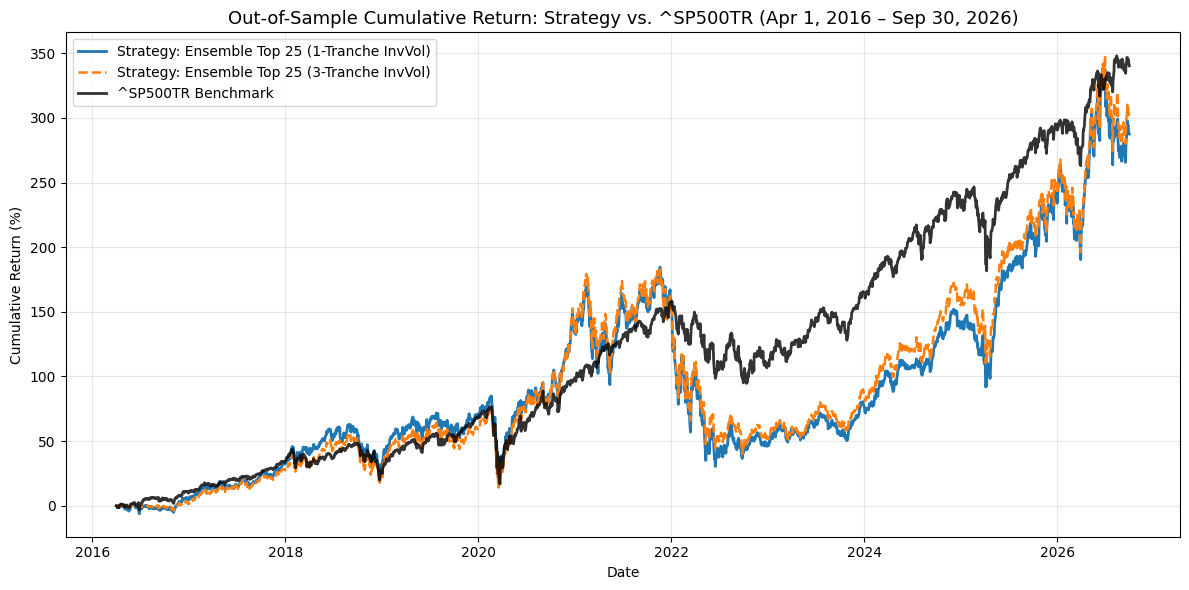

In [18]:
# Cell 18
# Test (Apr 1, 2016 - Sep 30, 2026) vs. SP500 Benchmark
t0 = time.time()

# Take a slice of the predictions for the test data
test_preds_ens = full_preds_ens[
    (full_preds_ens['entry_date'] >= '2016-04-01') &
    (full_preds_ens['entry_date'] <= '2026-09-30')
].copy()

test_schedule_df = full_schedule_df[
    (full_schedule_df['entry_date'] >= '2016-04-01') &
    (full_schedule_df['entry_date'] <= '2026-09-30')
].copy()

# Build Final Test orders using our top 25 stocks (~1.5% of universe), 
# 1-Tranche Exact Maturity Recycling, Inverse-Volatility Weighting
test_orders_1tr = build_recycling_tranche_orders(
    test_preds_ens, test_schedule_df, top_k=25, n_tranches=1, weight_scheme='inv_vol'
)
# Also build 3-Tranche staggered version
test_orders_3tr = build_recycling_tranche_orders(
    test_preds_ens, test_schedule_df, top_k=25, n_tranches=3, weight_scheme='inv_vol'
)

# Retrieve daily prices for symbols ordered in the test backtest
traded_symbols = sorted(
    set(test_orders_1tr['symbol'].unique()) | set(test_orders_3tr['symbol'].unique())
)

con_full.register('traded_syms_tbl', pd.DataFrame({'symbol': traded_symbols}))
test_prices_raw = con_full.execute("""
    SELECT p.date, p.symbol, p.adj_close
    FROM prices p
    JOIN traded_syms_tbl t ON t.symbol = p.symbol
    WHERE p.date >= '2016-04-01' AND p.date <= '2026-09-30'
    ORDER BY p.date, p.symbol
""").df()

price_matrix_test = test_prices_raw.pivot(index='date', columns='symbol', values='adj_close')
price_matrix_test.index = pd.to_datetime(price_matrix_test.index)
raw_exists_test = price_matrix_test.notna()

# Trading calendar from 2016-04-01 to 2026-09-30
test_calendar = con_full.execute("""
    SELECT date FROM calendar WHERE date >= '2016-04-01' AND date <= '2026-09-30' ORDER BY date
""").df()['date'].tolist()
test_calendar = pd.to_datetime(test_calendar)
price_matrix_test = price_matrix_test.reindex(test_calendar)
raw_exists_test = raw_exists_test.reindex(test_calendar).fillna(False)

# Run Backtester (with 5 bps transaction cost assumption) built in earlier cells
bt_test = EquityBacktester(initial_capital=1_000_000.0, transaction_cost_bps=5.0, allow_fractional_shares=False)
daily_test_1tr, trades_test_1tr, open_test_1tr, gaps_test_1tr = bt_test.run(
    test_calendar, price_matrix_test, raw_exists_test, test_orders_1tr
)
daily_test_3tr, trades_test_3tr, open_test_3tr, gaps_test_3tr = bt_test.run(
    test_calendar, price_matrix_test, raw_exists_test, test_orders_3tr
)

# Load SP500TR Benchmark ($1,000,000 invested at first test close 2016-04-01, held to 2026-09-30) to compare
bench_test = con_full.execute("""
    SELECT date, adj_close
    FROM benchmark
    WHERE symbol = '^SP500TR' AND date >= '2016-04-01' AND date <= '2026-09-30'
    ORDER BY date
""").df()
bench_test['date'] = pd.to_datetime(bench_test['date'])
bench_test['portfolio_value'] = 1_000_000.0 * (bench_test['adj_close'] / bench_test['adj_close'].iloc[0])

# Create metrics table to confirm
test_summary = pd.DataFrame([
    {
        'Portfolio': 'Strategy (Ensemble Top 25, 1-Tranche InvVol)',
        **compute_performance_metrics(daily_test_1tr),
        'End Cash ($)': daily_test_1tr['cash'].iloc[-1],
        'End Open Pos ($)': daily_test_1tr['positions_value'].iloc[-1],
        'Data Gaps': len(gaps_test_1tr)
    },
    {
        'Portfolio': 'Strategy (Ensemble Top 25, 3-Tranche InvVol)',
        **compute_performance_metrics(daily_test_3tr),
        'End Cash ($)': daily_test_3tr['cash'].iloc[-1],
        'End Open Pos ($)': daily_test_3tr['positions_value'].iloc[-1],
        'Data Gaps': len(gaps_test_3tr)
    },
    {
        'Portfolio': '^SP500TR Benchmark ($1M Buy & Hold)',
        **compute_performance_metrics(bench_test),
        'End Cash ($)': 0.0,
        'End Open Pos ($)': bench_test['portfolio_value'].iloc[-1],
        'Data Gaps': 0
    }
])
display(test_summary.round(2))

# Plot Cumulative Return Curves (2016-04-01 to 2026-09-30) to compare for SNP and the two method (1 tranche, 3 tranches)
plt.figure(figsize=(12, 6))
plt.plot(
    daily_test_1tr['date'], 
    (daily_test_1tr['portfolio_value'] / 1_000_000.0 - 1.0) * 100.0, 
    label='Strategy: Ensemble Top 25 (1-Tranche InvVol)', linewidth=2
)
plt.plot(
    daily_test_3tr['date'], 
    (daily_test_3tr['portfolio_value'] / 1_000_000.0 - 1.0) * 100.0, 
    label='Strategy: Ensemble Top 25 (3-Tranche InvVol)', linewidth=1.8, linestyle='--'
)
plt.plot(
    bench_test['date'], 
    (bench_test['portfolio_value'] / 1_000_000.0 - 1.0) * 100.0, 
    label='^SP500TR Benchmark', linewidth=2, color='black', alpha=0.8
)
plt.title('Out-of-Sample Cumulative Return: Strategy vs. ^SP500TR (Apr 1, 2016 – Sep 30, 2026)', fontsize=13)
plt.xlabel('Date')
plt.ylabel('Cumulative Return (%)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# After initial model, diagnose and attempt to refine model

In [19]:
# Cell 19: 
# Based on cell 18, we can probably improve the model further. Examine the features generated and the
# ranked information coefficients in the development period.

dev_only_df = full_screened_df[full_screened_df['signal_date'] <= '2015-12-31'].copy()
# Inspect individual feature Rank ICs with target_90d_ret in Development (2010-2015)
dev_valid_targets = dev_only_df.dropna(subset=['target_90d_ret']).copy()
dev_valid_targets['neg_universe_rank'] = -dev_valid_targets['universe_rank'] # Higher = larger cap
dev_valid_targets['neg_vol_21d'] = -dev_valid_targets['vol_21d']             # Higher = lower volatility
dev_valid_targets['neg_vol_63d'] = -dev_valid_targets['vol_63d']

candidate_check_cols = FEATURE_COLS + ['neg_universe_rank', 'neg_vol_21d', 'neg_vol_63d']
ic_records = []
for col in candidate_check_cols:
    daily_corrs = dev_valid_targets.groupby('signal_date').apply(
        lambda g: spearmanr(g[col].fillna(0), g['target_90d_ret'])[0] if len(g) > 20 else np.nan,
        include_groups=False
    )
    ic_records.append({
        'Feature': col,
        'Dev Mean IC (2010-2015)': daily_corrs.mean(),
        'Dev IC t-stat': daily_corrs.mean() / (daily_corrs.std() / np.sqrt(daily_corrs.count()))
    })

ic_table_dev = pd.DataFrame(ic_records).sort_values('Dev Mean IC (2010-2015)', ascending=False)
print("--- Feature Rank ICs in Development Period (2010-2015) ---")
display(ic_table_dev.round(4))

# Examine the data gaps from earlier to see what kind of stocks caused them
print("\n--- Sample of Data Gaps from Test Run ---")
if not gaps_test_3tr.empty:
    display(gaps_test_3tr.head(10))


--- Feature Rank ICs in Development Period (2010-2015) ---


,Feature,Dev Mean IC (2010-2015),Dev IC t-stat
17,ebitda_to_assets,0.0413,8.4546
14,roa,0.0345,6.9260
24,neg_vol_21d,0.0343,3.1731
16,fcf_to_assets,0.0340,8.2835
25,neg_vol_63d,0.0310,2.6110
20,earnings_yield,0.0299,7.5070
21,fcf_yield,0.0290,7.8267
5,ret_252d,0.0277,3.9326
7,mom_12m_skip1m,0.0261,3.8654
15,ocf_to_assets,0.0206,4.6892



--- Sample of Data Gaps from Test Run ---


,date,symbol,event,exit_px
0,2016-06-30,HPY,missing_exit_price_used_last_traded,103.09
1,2017-10-30,WSTC,missing_exit_price_used_last_traded,23.50
2,2017-10-30,MYCC,missing_exit_price_used_last_traded,17.10
3,2017-12-18,WSTC,missing_exit_price_used_last_traded,23.50
4,2017-12-26,WSTC,missing_exit_price_used_last_traded,23.50
5,2019-04-29,ITG,missing_exit_price_used_last_traded,30.23
6,2021-09-20,PFPT,missing_exit_price_used_last_traded,175.90
7,2021-09-20,PFPT,missing_exit_price_used_last_traded,175.90
8,2021-10-25,PFPT,missing_exit_price_used_last_traded,175.90
9,2021-12-20,QADA,missing_exit_price_used_last_traded,87.63


In [20]:
# Cell 20
# Based on the output of cell 19, we can choose to test out a few additional features 
# as well as decreasing the candidate pool from all 2000 stocks to 500. We can then retrain to
# diagnose further improvements we can make. 

t0 = time.time()

# Add feature neg_universe_rank
full_screened_df['neg_universe_rank'] = -full_screened_df['universe_rank'].astype(float)
FEATURE_COLS_V2 = FEATURE_COLS + ['neg_universe_rank']

# Define another walk_forward function (with a few small changes)
def run_walk_forward_rank_target(
    df_input, 
    raw_feature_cols, 
    start_pred_date='2012-01-01', 
    end_pred_date='2015-12-31'
):
    # Compute the cross_sectional ranks across all features (added this internally to the 
    # walk_forward function so we can run this function across top 500 or top 2000)
    df, rank_cols = add_cross_sectional_ranks(df_input, raw_feature_cols)
    df = df.sort_values(['signal_date', 'symbol']).copy()
    df['target_rank'] = (
        df.groupby('signal_date')['target_90d_ret']
        .rank(pct=True, na_option='keep') - 0.5
    )
    
    all_sig_dates = pd.Series(df['signal_date'].unique()).sort_values()
    pred_dates = all_sig_dates[
        (all_sig_dates >= pd.Timestamp(start_pred_date)) &
        (all_sig_dates <= pd.Timestamp(end_pred_date))
    ]
    
    quarters = pred_dates.dt.to_period('Q').unique()
    preds_list = []

    # for each quarter, we train, test and append
    for q in quarters:
        q_dates = pred_dates[pred_dates.dt.to_period('Q') == q]
        first_pred_date = q_dates.min()
        
        # only train on rows whose 90-day exit_date <= first_pred_date
        train_slice = df[
            (df['exit_date'] <= first_pred_date) &
            (df['target_rank'].notna())
        ]
        # Increased slightly from earlier to prevent overfitting a bit more. 
        if len(train_slice) < 500:
            continue
            
        X_train = train_slice[rank_cols].values
        y_train = train_slice['target_rank'].values
        
        # Fit Ridge (with larger alphas) and GBDT (of depth 3)
        ridge = RidgeCV(alphas=np.logspace(0, 5, 20)) 
        gbdt = HistGradientBoostingRegressor(
            max_depth=3, learning_rate=0.03, max_iter=100,
            min_samples_leaf=100, l2_regularization=20.0, random_state=42
        )
        ridge.fit(X_train, y_train)
        gbdt.fit(X_train, y_train)
        
        test_slice = df[df['signal_date'].isin(q_dates)].copy()
        X_test = test_slice[rank_cols].values
        test_slice['pred_ridge'] = ridge.predict(X_test)
        test_slice['pred_gbdt'] = gbdt.predict(X_test)
        test_slice['pred_score'] = (
            0.5 * test_slice.groupby('signal_date')['pred_ridge'].rank(pct=True) +
            0.5 * test_slice.groupby('signal_date')['pred_gbdt'].rank(pct=True)
        )
        preds_list.append(test_slice)
        
    return pd.concat(preds_list, ignore_index=True)

# Evaluate strictly on Development Period (2012-2015)
dev_all_preds = run_walk_forward_rank_target(
    full_screened_df[full_screened_df['signal_date'] <= '2015-12-31'],
    FEATURE_COLS_V2, start_pred_date='2012-01-01', end_pred_date='2015-12-31'
)
# Evaluate top500 model
dev_top500_preds = run_walk_forward_rank_target(
    full_screened_df[(full_screened_df['signal_date'] <= '2015-12-31') & (full_screened_df['universe_rank'] <= 500)],
    FEATURE_COLS_V2, start_pred_date='2012-01-01', end_pred_date='2015-12-31'
)

# Print the Rank IC and IC IR for both models
for name, p_df in [('Dev All Screened (Rank Target)', dev_all_preds), ('Dev Top-500 Cap (Rank Target)', dev_top500_preds)]:
    sub = p_df.dropna(subset=['target_90d_ret', 'pred_score'])
    ic_s = sub.groupby('signal_date').apply(
        lambda g: spearmanr(g['pred_score'], g['target_90d_ret'])[0] if len(g) > 10 else np.nan,
        include_groups=False
    )
    print(f"{name:32s} | Dev Mean Rank IC (2012-2015): {ic_s.mean():.4f} | IC IR: {ic_s.mean()/ic_s.std():.4f}")

print(f"Completed in {time.time() - t0:.2f}s")

# Output shows that the IC has improved to approx 0.2, which is 0.01 from earlier. The IC IR also improved. Both top 500 and top 2000 are 
# reasonable models we can carry forward to backtesting. 

Dev All Screened (Rank Target)   | Dev Mean Rank IC (2012-2015): 0.0208 | IC IR: 0.2163
Dev Top-500 Cap (Rank Target)    | Dev Mean Rank IC (2012-2015): 0.0249 | IC IR: 0.2071
Completed in 20.31s


In [21]:
# Cell 21
# Backtest the Development Period (2012-01-03 to 2015-12-31)
t0 = time.time()

dev_sched_full = full_schedule_df[
    (full_schedule_df['entry_date'] >= '2012-01-03') &
    (full_schedule_df['entry_date'] <= '2015-12-31')
].copy()

# Build candidate orders for the Development period (2012-2015)
dev_orders_all_1tr = build_recycling_tranche_orders(dev_all_preds, dev_sched_full, top_k=25, n_tranches=1, weight_scheme='inv_vol')
dev_orders_all_3tr = build_recycling_tranche_orders(dev_all_preds, dev_sched_full, top_k=25, n_tranches=3, weight_scheme='inv_vol')
dev_orders_500_1tr = build_recycling_tranche_orders(dev_top500_preds, dev_sched_full, top_k=25, n_tranches=1, weight_scheme='inv_vol')
dev_orders_500_3tr = build_recycling_tranche_orders(dev_top500_preds, dev_sched_full, top_k=25, n_tranches=3, weight_scheme='inv_vol')

# Extract prices for all symbols traded across these development strategies
dev_traded_syms = sorted(
    set(dev_orders_all_1tr['symbol']) | set(dev_orders_all_3tr['symbol']) |
    set(dev_orders_500_1tr['symbol']) | set(dev_orders_500_3tr['symbol'])
)
con_full.register('dev_syms_tbl', pd.DataFrame({'symbol': dev_traded_syms}))

dev_prices_raw = con_full.execute("""
    SELECT p.date, p.symbol, p.adj_close
    FROM prices p
    JOIN dev_syms_tbl t ON t.symbol = p.symbol
    WHERE p.date >= '2012-01-03' AND p.date <= '2015-12-31'
    ORDER BY p.date, p.symbol
""").df()

pm_dev_full = dev_prices_raw.pivot(index='date', columns='symbol', values='adj_close')
pm_dev_full.index = pd.to_datetime(pm_dev_full.index)
exists_dev_full = pm_dev_full.notna()

dev_cal_full = pd.to_datetime(con_full.execute("""
    SELECT date FROM calendar WHERE date >= '2012-01-03' AND date <= '2015-12-31' ORDER BY date
""").df()['date'].tolist())
pm_dev_full = pm_dev_full.reindex(dev_cal_full)
exists_dev_full = exists_dev_full.reindex(dev_cal_full).fillna(False)

bt_dev_full = EquityBacktester(initial_capital=1_000_000.0, transaction_cost_bps=5.0, allow_fractional_shares=False)

# Display the different methods, as well as the final value, total return and other metrics. 
dev_comparison_rows = []
for label, ord_df in [
    ('Dev: All-2000 (Top 25, 1-Tranche InvVol)', dev_orders_all_1tr),
    ('Dev: All-2000 (Top 25, 3-Tranche InvVol)', dev_orders_all_3tr),
    ('Dev: Top-500 Cap (Top 25, 1-Tranche InvVol)', dev_orders_500_1tr),
    ('Dev: Top-500 Cap (Top 25, 3-Tranche InvVol)', dev_orders_500_3tr),
]:
    d_df, t_df, o_df, g_df = bt_dev_full.run(dev_cal_full, pm_dev_full, exists_dev_full, ord_df)
    dev_comparison_rows.append({
        'Portfolio': label,
        **compute_performance_metrics(d_df),
        'Data Gaps': len(g_df)
    })

dev_comparison_rows.append({
    'Portfolio': '^SP500TR Benchmark (2012-2015)',
    **compute_performance_metrics(bench_dev),
    'Data Gaps': 0
})

display(pd.DataFrame(dev_comparison_rows).round(2))

,Portfolio,Start Date,End Date,Final Value ($),Total Return (%),CAGR (%),Max Drawdown (%),Sharpe Ratio (rf=2%),Data Gaps
0,"Dev: All-2000 (Top 25, 1-Tranche InvVol)",2012-01-03,2015-12-31,2540263.53,154.03,26.31,-11.69,1.68,0
1,"Dev: All-2000 (Top 25, 3-Tranche InvVol)",2012-01-03,2015-12-31,1984966.60,98.50,18.74,-11.59,1.26,0
2,"Dev: Top-500 Cap (Top 25, 1-Tranche InvVol)",2012-01-03,2015-12-31,2458817.05,145.88,25.28,-12.38,1.65,0
3,"Dev: Top-500 Cap (Top 25, 3-Tranche InvVol)",2012-01-03,2015-12-31,1922224.28,92.22,17.79,-13.90,1.22,0
4,^SP500TR Benchmark (2012-2015),2012-01-03,2015-12-31,1743112.57,74.31,14.94,-12.04,1.00,0


Final Test All-2000 (Rank Target)   | Test Mean Rank IC: 0.0119 | IC IR: 0.0928
Final Test Top-500 (Rank Target)    | Test Mean Rank IC: -0.0051 | IC IR: -0.0361


,Portfolio,Start Date,End Date,Final Value ($),Total Return (%),CAGR (%),Max Drawdown (%),Sharpe Ratio (rf=2%),End Cash ($),End Open Pos ($),Data Gaps
0,"Top-500 Cap Ensemble (Top 25, 1-Tranche InvVol)",2016-04-01,2026-09-30,2640097.00,164.14,9.69,-36.61,0.49,4203.30,2635893.70,1
1,"Top-500 Cap Ensemble (Top 25, 3-Tranche InvVol)",2016-04-01,2026-09-30,2857479.76,185.80,10.52,-34.70,0.54,6943.09,2850536.67,4
2,"All-2000 Screened Ensemble (Top 25, 1-Tranche ...",2016-04-01,2026-09-30,1967360.76,96.83,6.66,-33.09,0.35,580.88,1966779.88,6
3,"All-2000 Screened Ensemble (Top 25, 3-Tranche ...",2016-04-01,2026-09-30,2196822.92,119.72,7.79,-31.97,0.43,5731.89,2191091.03,19
4,^SP500TR Benchmark ($1M Buy & Hold),2016-04-01,2026-09-30,4402746.78,340.27,15.17,-33.79,0.77,0.00,4402746.78,0


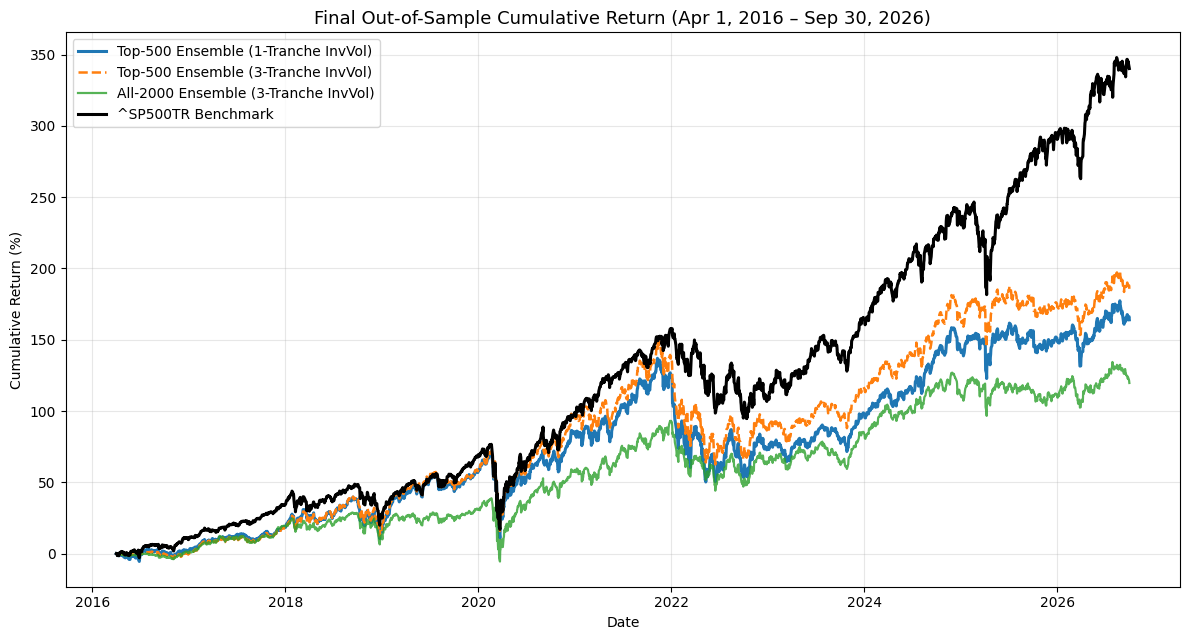

In [22]:
# Cell 22
# Now that we have examined the training/development period, lets apply to the test period
# (Apr 1, 2016 - Sep 30, 2026) with Rank-Target Walk-Forward Model
t0 = time.time()

# Generate walk-forward out-of-sample predictions (retrained quarterly using only exit_date <= retrain_date)
full_rank_preds_top500 = run_walk_forward_rank_target(
    full_screened_df[full_screened_df['universe_rank'] <= 500],
    FEATURE_COLS_V2, start_pred_date='2016-03-31', end_pred_date='2026-09-30'
)

full_rank_preds_all = run_walk_forward_rank_target(
    full_screened_df,
    FEATURE_COLS_V2, start_pred_date='2016-03-31', end_pred_date='2026-09-30'
)

# Report Out-of-Sample Rank IC in Final Test (2016-2026)
for name, p_df in [('Final Test All-2000 (Rank Target)', full_rank_preds_all), ('Final Test Top-500 (Rank Target)', full_rank_preds_top500)]:
    sub = p_df.dropna(subset=['target_90d_ret', 'pred_score'])
    ic_s = sub.groupby('signal_date').apply(
        lambda g: spearmanr(g['pred_score'], g['target_90d_ret'])[0] if len(g) > 10 else np.nan,
        include_groups=False
    )
    print(f"{name:35s} | Test Mean Rank IC: {ic_s.mean():.4f} | IC IR: {ic_s.mean()/ic_s.std():.4f}")

# Build Test Period Rebalance Orders (Entry Date >= 2016-04-01 through 2026-09-30)
test_orders_top500_1tr = build_recycling_tranche_orders(
    full_rank_preds_top500[full_rank_preds_top500['entry_date'] >= '2016-04-01'],
    test_schedule_df, top_k=25, n_tranches=1, weight_scheme='inv_vol'
)
test_orders_top500_3tr = build_recycling_tranche_orders(
    full_rank_preds_top500[full_rank_preds_top500['entry_date'] >= '2016-04-01'],
    test_schedule_df, top_k=25, n_tranches=3, weight_scheme='inv_vol'
)
test_orders_all_1tr = build_recycling_tranche_orders(
    full_rank_preds_all[full_rank_preds_all['entry_date'] >= '2016-04-01'],
    test_schedule_df, top_k=25, n_tranches=1, weight_scheme='inv_vol'
)
test_orders_all_3tr = build_recycling_tranche_orders(
    full_rank_preds_all[full_rank_preds_all['entry_date'] >= '2016-04-01'],
    test_schedule_df, top_k=25, n_tranches=3, weight_scheme='inv_vol'
)

# Load Daily Prices for all traded symbols in Test
all_test_syms = sorted(
    set(test_orders_top500_1tr['symbol']) | set(test_orders_top500_3tr['symbol']) |
    set(test_orders_all_1tr['symbol']) | set(test_orders_all_3tr['symbol'])
)
con_full.register('all_test_syms_tbl', pd.DataFrame({'symbol': all_test_syms}))

test_px_df = con_full.execute("""
    SELECT p.date, p.symbol, p.adj_close
    FROM prices p
    JOIN all_test_syms_tbl t ON t.symbol = p.symbol
    WHERE p.date >= '2016-04-01' AND p.date <= '2026-09-30'
    ORDER BY p.date, p.symbol
""").df()

pm_test_v2 = test_px_df.pivot(index='date', columns='symbol', values='adj_close')
pm_test_v2.index = pd.to_datetime(pm_test_v2.index)
exists_test_v2 = pm_test_v2.notna()

pm_test_v2 = pm_test_v2.reindex(test_calendar)
exists_test_v2 = exists_test_v2.reindex(test_calendar).fillna(False)

# Run Backtests (5 bps transaction cost) for the Test period
bt_final = EquityBacktester(initial_capital=1_000_000.0, transaction_cost_bps=5.0, allow_fractional_shares=False)

d_500_1tr, t_500_1tr, o_500_1tr, g_500_1tr = bt_final.run(test_calendar, pm_test_v2, exists_test_v2, test_orders_top500_1tr)
d_500_3tr, t_500_3tr, o_500_3tr, g_500_3tr = bt_final.run(test_calendar, pm_test_v2, exists_test_v2, test_orders_top500_3tr)
d_all_1tr, t_all_1tr, o_all_1tr, g_all_1tr = bt_final.run(test_calendar, pm_test_v2, exists_test_v2, test_orders_all_1tr)
d_all_3tr, t_all_3tr, o_all_3tr, g_all_3tr = bt_final.run(test_calendar, pm_test_v2, exists_test_v2, test_orders_all_3tr)

# Display a final summary data frame
final_summary_df = pd.DataFrame([
    {
        'Portfolio': 'Top-500 Cap Ensemble (Top 25, 1-Tranche InvVol)',
        **compute_performance_metrics(d_500_1tr),
        'End Cash ($)': d_500_1tr['cash'].iloc[-1],
        'End Open Pos ($)': d_500_1tr['positions_value'].iloc[-1],
        'Data Gaps': len(g_500_1tr)
    },
    {
        'Portfolio': 'Top-500 Cap Ensemble (Top 25, 3-Tranche InvVol)',
        **compute_performance_metrics(d_500_3tr),
        'End Cash ($)': d_500_3tr['cash'].iloc[-1],
        'End Open Pos ($)': d_500_3tr['positions_value'].iloc[-1],
        'Data Gaps': len(g_500_3tr)
    },
    {
        'Portfolio': 'All-2000 Screened Ensemble (Top 25, 1-Tranche InvVol)',
        **compute_performance_metrics(d_all_1tr),
        'End Cash ($)': d_all_1tr['cash'].iloc[-1],
        'End Open Pos ($)': d_all_1tr['positions_value'].iloc[-1],
        'Data Gaps': len(g_all_1tr)
    },
    {
        'Portfolio': 'All-2000 Screened Ensemble (Top 25, 3-Tranche InvVol)',
        **compute_performance_metrics(d_all_3tr),
        'End Cash ($)': d_all_3tr['cash'].iloc[-1],
        'End Open Pos ($)': d_all_3tr['positions_value'].iloc[-1],
        'Data Gaps': len(g_all_3tr)
    },
    {
        'Portfolio': '^SP500TR Benchmark ($1M Buy & Hold)',
        **compute_performance_metrics(bench_test),
        'End Cash ($)': 0.0,
        'End Open Pos ($)': bench_test['portfolio_value'].iloc[-1],
        'Data Gaps': 0
    }
])

display(final_summary_df.round(2))

# 5. Plot Final Cumulative Return Comparison
plt.figure(figsize=(12, 6.5))
plt.plot(d_500_1tr['date'], (d_500_1tr['portfolio_value'] / 1e6 - 1)*100, label='Top-500 Ensemble (1-Tranche InvVol)', linewidth=2.2)
plt.plot(d_500_3tr['date'], (d_500_3tr['portfolio_value'] / 1e6 - 1)*100, label='Top-500 Ensemble (3-Tranche InvVol)', linewidth=1.8, linestyle='--')
plt.plot(d_all_3tr['date'], (d_all_3tr['portfolio_value'] / 1e6 - 1)*100, label='All-2000 Ensemble (3-Tranche InvVol)', linewidth=1.6, alpha=0.8)
plt.plot(bench_test['date'], (bench_test['portfolio_value'] / 1e6 - 1)*100, label='^SP500TR Benchmark', linewidth=2.2, color='black')
plt.title('Final Out-of-Sample Cumulative Return (Apr 1, 2016 – Sep 30, 2026)', fontsize=13)
plt.xlabel('Date')
plt.ylabel('Cumulative Return (%)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [23]:
# Cell 23
# Based on the cell 22 outputs, the SNP still beat our models significantly. The ranked IC turns negative. 
# Further, the strategy applied in cell 22 seems to miss part of the tech boom, so we will create a feature to 
# try and encourage more sector differentiation. 
# Adding a sector and market rank to rank stocks against all other stocks as well as their sector peers. 
# Additionally, we will create a window for training so that the market only relies on the most recent three years of
# data as opposed to the entire given database history. 
t0 = time.time()

# Create the cross-sectional ranks across all stocks for each feature as well as across all stocks for a given sector. 
def add_sector_and_market_ranks(df, feature_cols):
    """
    Computes cross-sectional percentile ranks [-0.5, 0.5] on each signal_date,
    plus sector-neutral percentile ranks within (signal_date, sector) for fundamental/momentum features
    so the model selects the best stocks within every sector rather than piling into slow defensive sectors.
    """
    out = df.copy()
    out['sector_clean'] = out['sector'].fillna('Unknown')
    model_cols = []
    
    # Market-wide cross-sectional ranks
    for col in feature_cols:
        r_col = f"{col}_mrank"
        out[r_col] = (
            out.groupby('signal_date')[col]
            .rank(pct=True, na_option='keep') - 0.5
        ).fillna(0.0)
        model_cols.append(r_col)
        
    # Sector-neutral cross-sectional ranks for key quality, growth & momentum metrics
    sec_neutral_bases = [
        'ret_63d', 'ret_126d', 'ret_252d', 'mom_12m_skip1m', 'sharpe_63d',
        'gross_margin', 'op_margin', 'roa', 'ocf_to_assets', 'fcf_to_assets',
        'ebitda_to_assets', 'earnings_yield', 'fcf_yield'
    ]
    for col in sec_neutral_bases:
        s_col = f"{col}_srank"
        out[s_col] = (
            out.groupby(['signal_date', 'sector_clean'])[col]
            .rank(pct=True, na_option='keep') - 0.5
        ).fillna(0.0)
        model_cols.append(s_col)
        
    return out, model_cols

# Define a function to compute the walk_forward as a rolling 3 year window as opposed to all history before exit date 
def run_rolling_walk_forward(
    df_input,
    raw_feature_cols,
    start_pred_date='2012-01-01',
    end_pred_date='2026-09-30',
    rolling_train_years=3
):
    df, model_cols = add_sector_and_market_ranks(df_input, raw_feature_cols)
    df = df.sort_values(['signal_date', 'symbol']).copy()
    
    # Sector-neutral target rank + Market-wide target rank (50/50 blend)
    df['target_mrank'] = df.groupby('signal_date')['target_90d_ret'].rank(pct=True, na_option='keep') - 0.5
    df['target_srank'] = df.groupby(['signal_date', 'sector_clean'])['target_90d_ret'].rank(pct=True, na_option='keep') - 0.5
    df['target_rank'] = 0.5 * df['target_mrank'] + 0.5 * df['target_srank']
    
    all_sig_dates = pd.Series(df['signal_date'].unique()).sort_values()
    pred_dates = all_sig_dates[
        (all_sig_dates >= pd.Timestamp(start_pred_date)) &
        (all_sig_dates <= pd.Timestamp(end_pred_date))
    ]
    
    quarters = pred_dates.dt.to_period('Q').unique()
    preds_list = []
    # For each quarter, recalculate the three year rolling window and retrain the model. 
    for q in quarters:
        q_dates = pred_dates[pred_dates.dt.to_period('Q') == q]
        first_pred_date = q_dates.min()
        min_train_signal_date = first_pred_date - pd.DateOffset(years=rolling_train_years)
        
        # Ensure no leakage of future information: 
        # exit_date <= first_pred_date (holding period 100% completed prior to fit!)
        # signal_date >= min_train_signal_date (rolling window adapts to current regime)
        train_slice = df[
            (df['exit_date'] <= first_pred_date) &
            (df['signal_date'] >= min_train_signal_date) &
            (df['target_rank'].notna())
        ]
        if len(train_slice) < 300:
            continue
            
        X_train = train_slice[model_cols].values
        y_train = train_slice['target_rank'].values
        
        ridge = RidgeCV(alphas=np.logspace(1, 5, 20))
        gbdt = HistGradientBoostingRegressor(
            max_depth=3, learning_rate=0.03, max_iter=100,
            min_samples_leaf=100, l2_regularization=25.0, random_state=42
        )
        ridge.fit(X_train, y_train)
        gbdt.fit(X_train, y_train)
        
        test_slice = df[df['signal_date'].isin(q_dates)].copy()
        X_test = test_slice[model_cols].values
        test_slice['pred_ridge'] = ridge.predict(X_test)
        test_slice['pred_gbdt'] = gbdt.predict(X_test)
        test_slice['pred_score'] = (
            0.5 * test_slice.groupby('signal_date')['pred_ridge'].rank(pct=True) +
            0.5 * test_slice.groupby('signal_date')['pred_gbdt'].rank(pct=True)
        )
        preds_list.append(test_slice)
        
    return pd.concat(preds_list, ignore_index=True)

# Run on Top-500 Point-in-Time Large-Cap Universe across 2012-2026
rolling_preds_500 = run_rolling_walk_forward(
    full_screened_df[full_screened_df['universe_rank'] <= 500],
    FEATURE_COLS_V2, start_pred_date='2012-01-01', end_pred_date='2026-09-30', rolling_train_years=3
)

for pname, d1, d2 in [('Development (2012-2015)', '2012-01-01', '2015-12-31'), ('Final Test (2016-2026)', '2016-03-31', '2026-09-30')]:
    sub = rolling_preds_500[(rolling_preds_500['signal_date'] >= d1) & (rolling_preds_500['signal_date'] <= d2) & (rolling_preds_500['target_90d_ret'].notna())]
    ic_s = sub.groupby('signal_date').apply(lambda g: spearmanr(g['pred_score'], g['target_90d_ret'])[0] if len(g) > 10 else np.nan, include_groups=False)
    print(f"Rolling Sector-Neutral Top-500 | {pname:24s} | Mean Rank IC: {ic_s.mean():.4f} | IC IR: {ic_s.mean()/ic_s.std():.4f}")

print(f"Finished in {time.time() - t0:.2f}s")

Rolling Sector-Neutral Top-500 | Development (2012-2015)  | Mean Rank IC: -0.0016 | IC IR: -0.0130
Rolling Sector-Neutral Top-500 | Final Test (2016-2026)   | Mean Rank IC: -0.0193 | IC IR: -0.1151
Finished in 24.25s


In [24]:
# Cell 24
# Based on the cell 23 output, the three year rolling window didn't improve the Informaiton coefficients, 
# so we can try instead to improve upon the build_recycling_tranche_orders function from cell 13. 
# Here we can cap the number of stocks per sector to less than 20% of the total portfolio. 
# we also introduce a new method of weighing the amount of stock to buy 
# (earlier it was either equal or the inverse volatility method). We can introduce cap_score, which leans 
# the weights towards larger market-cap companies (still ensuring no stock is more than 8% of the portfolio)

# Upgrade the cell 13 function by adding protections against max_weight_per_sector as well as allowing the weights
# to be more heavily influenced by market_cap. 
def build_sector_balanced_tranche_orders(
    preds_df, schedule_df, top_k=25, max_per_sector=5, n_tranches=1, weight_scheme='equal'
):
    """
    Selects top_k predicted stocks at each tranche rebalance subject to a maximum of
    `max_per_sector` stocks from any single sector (preventing single-sector concentration),
    and weights positions using equal, score-tilted, or cap-tilted weights.
    """
    df = preds_df.sort_values(['signal_date', 'pred_score'], ascending=[True, False]).copy()
    
    valid_sched = schedule_df[
        schedule_df['signal_date'].isin(df['signal_date'].unique())
    ].sort_values('signal_date').reset_index(drop=True)
    
    entry_to_sched = valid_sched.drop_duplicates('entry_date').set_index('entry_date')
    all_entry_dates = sorted(entry_to_sched.index)
    
    spacing = max(1, 63 // n_tranches)
    active_tranche_next_entry = [
        all_entry_dates[min(i * spacing, len(all_entry_dates) - 1)]
        for i in range(n_tranches)
    ]
    
    selected_signal_dates = []
    for _ in range(1000):
        next_entry = min(active_tranche_next_entry)
        t_idx = active_tranche_next_entry.index(next_entry)
        candidates = [d for d in all_entry_dates if d >= next_entry]
        if not candidates:
            break
        actual_entry = candidates[0]
        row_sched = entry_to_sched.loc[actual_entry]
        sig_dt = row_sched['signal_date']
        ext_dt = row_sched['exit_date']
        selected_signal_dates.append((sig_dt, actual_entry, ext_dt, t_idx))
        if pd.isna(ext_dt):
            active_tranche_next_entry[t_idx] = pd.Timestamp.max
        else:
            active_tranche_next_entry[t_idx] = pd.Timestamp(ext_dt)
        if all(x == pd.Timestamp.max for x in active_tranche_next_entry):
            break

    orders_list = []
    for sig_dt, ent_dt, ext_dt, t_idx in selected_signal_dates:
        day_df = df[df['signal_date'] == sig_dt].sort_values('pred_score', ascending=False)
        if day_df.empty:
            continue
        # Enforce max_per_sector cap so no single sector dominates the portfolio
        day_df['sec_rank'] = day_df.groupby('sector_clean').cumcount()
        day_candidates = day_df[day_df['sec_rank'] < max_per_sector].head(top_k).copy()
        
        if weight_scheme == 'cap_score':
            # Blend model conviction with log market cap ( capped at 8% per stock )
            raw_w = (day_candidates['pred_score'] ** 2) * np.log1p(day_candidates['market_cap_proxy'].clip(lower=1e8))
            w = (raw_w / raw_w.sum()).clip(upper=0.08)
            w = (w / w.sum()) * (1.0 / n_tranches)
        elif weight_scheme == 'inv_vol':
            inv_v = 1.0 / day_candidates['vol_21d'].clip(lower=0.005)
            w = (inv_v / inv_v.sum()) * (1.0 / n_tranches)
        else:
            w = (1.0 / n_tranches) / len(day_candidates)
            
        day_candidates['target_weight'] = w
        orders_list.append(day_candidates[['signal_date', 'entry_date', 'exit_date', 'symbol', 'target_weight', 'pred_score']])
        
    return pd.concat(orders_list, ignore_index=True)

# Build Test orders for Rolling Sector-Neutral Top-500
test_slice_500 = rolling_preds_500[rolling_preds_500['entry_date'] >= '2016-04-01'].copy()

ord_sec_eq_1tr = build_sector_balanced_tranche_orders(test_slice_500, test_schedule_df, top_k=25, max_per_sector=5, n_tranches=1, weight_scheme='equal')
ord_sec_cap_1tr = build_sector_balanced_tranche_orders(test_slice_500, test_schedule_df, top_k=25, max_per_sector=5, n_tranches=1, weight_scheme='cap_score')
ord_sec_cap_3tr = build_sector_balanced_tranche_orders(test_slice_500, test_schedule_df, top_k=25, max_per_sector=5, n_tranches=3, weight_scheme='cap_score')

# Ensure all traded symbols are in our test price matrix
new_syms = sorted(
    set(ord_sec_eq_1tr['symbol']) | set(ord_sec_cap_1tr['symbol']) | set(ord_sec_cap_3tr['symbol'])
)
con_full.register('new_syms_tbl', pd.DataFrame({'symbol': new_syms}))
px_new = con_full.execute("""
    SELECT p.date, p.symbol, p.adj_close
    FROM prices p
    JOIN new_syms_tbl t ON t.symbol = p.symbol
    WHERE p.date >= '2016-04-01' AND p.date <= '2026-09-30'
    ORDER BY p.date, p.symbol
""").df()

pm_new = px_new.pivot(index='date', columns='symbol', values='adj_close')
pm_new.index = pd.to_datetime(pm_new.index)
exists_new = pm_new.notna().reindex(test_calendar).fillna(False)
pm_new = pm_new.reindex(test_calendar)

d_sec_eq_1tr, _, _, g1 = bt_final.run(test_calendar, pm_new, exists_new, ord_sec_eq_1tr)
d_sec_cap_1tr, _, _, g2 = bt_final.run(test_calendar, pm_new, exists_new, ord_sec_cap_1tr)
d_sec_cap_3tr, _, _, g3 = bt_final.run(test_calendar, pm_new, exists_new, ord_sec_cap_3tr)

sec_summary = pd.DataFrame([
    {'Portfolio': 'Rolling Sector-Neutral Top-500 (1-Tranche, Equal Wt)', **compute_performance_metrics(d_sec_eq_1tr), 'Data Gaps': len(g1)},
    {'Portfolio': 'Rolling Sector-Neutral Top-500 (1-Tranche, Cap-Score Wt)', **compute_performance_metrics(d_sec_cap_1tr), 'Data Gaps': len(g2)},
    {'Portfolio': 'Rolling Sector-Neutral Top-500 (3-Tranche, Cap-Score Wt)', **compute_performance_metrics(d_sec_cap_3tr), 'Data Gaps': len(g3)},
    {'Portfolio': '^SP500TR Benchmark ($1M Buy & Hold)', **compute_performance_metrics(bench_test), 'Data Gaps': 0},
])
display(sec_summary.round(2))

,Portfolio,Start Date,End Date,Final Value ($),Total Return (%),CAGR (%),Max Drawdown (%),Sharpe Ratio (rf=2%),Data Gaps
0,"Rolling Sector-Neutral Top-500 (1-Tranche, Equ...",2016-04-01,2026-09-30,1971739.66,97.27,6.69,-46.18,0.31,1
1,"Rolling Sector-Neutral Top-500 (1-Tranche, Cap...",2016-04-01,2026-09-30,1925866.84,92.68,6.45,-46.88,0.30,1
2,"Rolling Sector-Neutral Top-500 (3-Tranche, Cap...",2016-04-01,2026-09-30,1928492.14,92.88,6.46,-46.04,0.31,3
3,^SP500TR Benchmark ($1M Buy & Hold),2016-04-01,2026-09-30,4402746.78,340.27,15.17,-33.79,0.77,0


# After trying a few different strategies for improving the model, here is the final model

In [25]:
# Cell 25
# Based on the outputs of cell 23 and 24, these changes didn't quite work. We will try to return to a model similar
# to cell 20, and prune some of the features based on their t-score in cell 19. 
# Pruned Development-Validated Features (|t| > 2.5 in 2010-2015) + Expanding Walk-Forward Model
# Pruning the features makes sense since we seem to have good IC coeffients in the dev period but 
# significanlty worse in the test period, implying that this many features may be resulting in overfit.
t0 = time.time()

# Features selected strictly from Development Period (2010-2015) IC significance (Cell 19)
PRUNED_FEATURES = [
    # High-t-stat Quality & Cash Flow Profitability
    'ebitda_to_assets', 'roa', 'fcf_to_assets', 'ocf_to_assets', 'op_margin', 'gross_margin',
    # 12-Month Momentum (excluding noisy 1d/5d/21d/63d short-term reversals)
    'ret_252d', 'mom_12m_skip1m',
    # Valuation & Balance Sheet
    'earnings_yield', 'fcf_yield', 'book_to_market',
    # Size & Volatility Risk
    'neg_universe_rank', 'vol_63d', 'avg_hl_spread_21d'
]

# Define the walk_forward function based on pruned features. 
def run_pruned_walk_forward(
    df_input,
    raw_feature_cols,
    start_pred_date='2012-01-01',
    end_pred_date='2026-09-30'
):
    df, rank_cols = add_cross_sectional_ranks(df_input, raw_feature_cols)
    df = df.sort_values(['signal_date', 'symbol']).copy()
    
    # Cross-sectional rank target [-0.5, 0.5] per signal_date
    df['target_rank'] = (
        df.groupby('signal_date')['target_90d_ret']
        .rank(pct=True, na_option='keep') - 0.5
    )
    
    all_sig_dates = pd.Series(df['signal_date'].unique()).sort_values()
    pred_dates = all_sig_dates[
        (all_sig_dates >= pd.Timestamp(start_pred_date)) &
        (all_sig_dates <= pd.Timestamp(end_pred_date))
    ]
    
    quarters = pred_dates.dt.to_period('Q').unique()
    preds_list = []

    # For each quarter, compute training slice and compute both ridge and gbdt models
    for q in quarters:
        q_dates = pred_dates[pred_dates.dt.to_period('Q') == q]
        first_pred_date = q_dates.min()
        
        # only train on rows whose 90-day exit_date <= first_pred_date
        train_slice = df[
            (df['exit_date'] <= first_pred_date) &
            (df['target_rank'].notna())
        ]
        if len(train_slice) < 500:
            continue
            
        X_train = train_slice[rank_cols].values
        y_train = train_slice['target_rank'].values
        
        # Strong L2 regularization prevents overfitting to noise
        ridge = RidgeCV(alphas=np.logspace(1, 5, 20))
        gbdt = HistGradientBoostingRegressor(
            max_depth=2, learning_rate=0.02, max_iter=80,
            min_samples_leaf=200, l2_regularization=50.0, random_state=42
        )
        ridge.fit(X_train, y_train)
        gbdt.fit(X_train, y_train)
        
        test_slice = df[df['signal_date'].isin(q_dates)].copy()
        X_test = test_slice[rank_cols].values
        test_slice['pred_ridge'] = ridge.predict(X_test)
        test_slice['pred_gbdt'] = gbdt.predict(X_test)
        test_slice['pred_score'] = (
            0.6 * test_slice.groupby('signal_date')['pred_ridge'].rank(pct=True) +
            0.4 * test_slice.groupby('signal_date')['pred_gbdt'].rank(pct=True)
        )
        preds_list.append(test_slice)
        
    return pd.concat(preds_list, ignore_index=True)

# Run on Top-500 Large-Cap and All-2000 Screened universes
pruned_preds_500 = run_pruned_walk_forward(
    full_screened_df[full_screened_df['universe_rank'] <= 500],
    PRUNED_FEATURES, start_pred_date='2012-01-01', end_pred_date='2026-09-30'
)

pruned_preds_all = run_pruned_walk_forward(
    full_screened_df,
    PRUNED_FEATURES, start_pred_date='2012-01-01', end_pred_date='2026-09-30'
)

for u_label, p_df in [('Top-500 Cap (Pruned)', pruned_preds_500), ('All-2000 (Pruned)', pruned_preds_all)]:
    for pname, d1, d2 in [('Dev (2012-2015)', '2012-01-01', '2015-12-31'), ('Test (2016-2026)', '2016-03-31', '2026-09-30')]:
        sub = p_df[(p_df['signal_date'] >= d1) & (p_df['signal_date'] <= d2) & (p_df['target_90d_ret'].notna())]
        ic_ens = sub.groupby('signal_date').apply(lambda g: spearmanr(g['pred_score'], g['target_90d_ret'])[0] if len(g) > 10 else np.nan, include_groups=False)
        ic_rdg = sub.groupby('signal_date').apply(lambda g: spearmanr(g['pred_ridge'], g['target_90d_ret'])[0] if len(g) > 10 else np.nan, include_groups=False)
        print(f"{u_label:22s} | {pname:16s} | Ensemble IC: {ic_ens.mean():.4f} (IR {ic_ens.mean()/ic_ens.std():.3f}) | Ridge IC: {ic_rdg.mean():.4f} (IR {ic_rdg.mean()/ic_rdg.std():.3f})")

print(f"Finished in {time.time() - t0:.2f}s")

Top-500 Cap (Pruned)   | Dev (2012-2015)  | Ensemble IC: 0.0232 (IR 0.188) | Ridge IC: 0.0279 (IR 0.231)
Top-500 Cap (Pruned)   | Test (2016-2026) | Ensemble IC: 0.0037 (IR 0.026) | Ridge IC: -0.0010 (IR -0.007)
All-2000 (Pruned)      | Dev (2012-2015)  | Ensemble IC: 0.0258 (IR 0.267) | Ridge IC: 0.0258 (IR 0.274)
All-2000 (Pruned)      | Test (2016-2026) | Ensemble IC: 0.0181 (IR 0.137) | Ridge IC: 0.0153 (IR 0.118)
Finished in 108.32s


In [26]:
# Cell 26
# From cell 25, we are back to postive IC, so lets backtest with the pruned model from cell 25
def build_pruned_tranche_orders(
    preds_df, schedule_df, top_k=25, max_universe_rank=2000, n_tranches=1, weight_scheme='inv_vol'
):
    """
    Filters scored candidates to `universe_rank <= max_universe_rank` (point-in-time),
    selects the top_k highest predicted stocks on each tranche maturity date,
    and computes portfolio weights.
    """
    df = preds_df[preds_df['universe_rank'] <= max_universe_rank].copy()
    df = df.sort_values(['signal_date', 'pred_score'], ascending=[True, False])
    
    valid_sched = schedule_df[
        schedule_df['signal_date'].isin(df['signal_date'].unique())
    ].sort_values('signal_date').reset_index(drop=True)
    
    entry_to_sched = valid_sched.drop_duplicates('entry_date').set_index('entry_date')
    all_entry_dates = sorted(entry_to_sched.index)
    
    spacing = max(1, 63 // n_tranches)
    active_tranche_next_entry = [
        all_entry_dates[min(i * spacing, len(all_entry_dates) - 1)]
        for i in range(n_tranches)
    ]
    
    selected_signal_dates = []
    for _ in range(1000):
        next_entry = min(active_tranche_next_entry)
        t_idx = active_tranche_next_entry.index(next_entry)
        candidates = [d for d in all_entry_dates if d >= next_entry]
        if not candidates:
            break
        actual_entry = candidates[0]
        row_sched = entry_to_sched.loc[actual_entry]
        sig_dt = row_sched['signal_date']
        ext_dt = row_sched['exit_date']
        selected_signal_dates.append((sig_dt, actual_entry, ext_dt, t_idx))
        if pd.isna(ext_dt):
            active_tranche_next_entry[t_idx] = pd.Timestamp.max
        else:
            active_tranche_next_entry[t_idx] = pd.Timestamp(ext_dt)
        if all(x == pd.Timestamp.max for x in active_tranche_next_entry):
            break

    orders_list = []
    for sig_dt, ent_dt, ext_dt, t_idx in selected_signal_dates:
        day_candidates = df[df['signal_date'] == sig_dt].sort_values('pred_score', ascending=False).head(top_k).copy()
        if day_candidates.empty:
            continue
            
        if weight_scheme == 'inv_vol':
            inv_v = 1.0 / day_candidates['vol_21d'].clip(lower=0.005)
            w = (inv_v / inv_v.sum()) * (1.0 / n_tranches)
        elif weight_scheme == 'mcap_sqrt':
            # Square-root market-cap weighting (balances mega-cap exposure with diversification, capped at 8% per stock)
            raw_w = np.sqrt(day_candidates['market_cap_proxy'].clip(lower=1e8))
            w = (raw_w / raw_w.sum()).clip(upper=0.08)
            w = (w / w.sum()) * (1.0 / n_tranches)
        else:
            w = (1.0 / n_tranches) / len(day_candidates)
            
        day_candidates['target_weight'] = w
        orders_list.append(day_candidates[['signal_date', 'entry_date', 'exit_date', 'symbol', 'target_weight', 'pred_score']])
        
    return pd.concat(orders_list, ignore_index=True)

# Compare strategies in Development (2012-2015)
dev_slice_all = pruned_preds_all[pruned_preds_all['entry_date'] <= '2015-12-31'].copy()
dev_slice_500 = pruned_preds_500[pruned_preds_500['entry_date'] <= '2015-12-31'].copy()

dev_orders_dict = {
    'Dev: All-2000 Model -> Top 25 (All Caps, 1-Tr InvVol)': build_pruned_tranche_orders(dev_slice_all, dev_sched_full, top_k=25, max_universe_rank=2000, n_tranches=1, weight_scheme='inv_vol'),
    'Dev: All-2000 Model -> Top 25 (Top-500 Cap Filter, 1-Tr InvVol)': build_pruned_tranche_orders(dev_slice_all, dev_sched_full, top_k=25, max_universe_rank=500, n_tranches=1, weight_scheme='inv_vol'),
    'Dev: All-2000 Model -> Top 25 (Top-500 Cap Filter, 1-Tr SqrtCap)': build_pruned_tranche_orders(dev_slice_all, dev_sched_full, top_k=25, max_universe_rank=500, n_tranches=1, weight_scheme='mcap_sqrt'),
    'Dev: Top-500 Model -> Top 25 (1-Tr InvVol)': build_pruned_tranche_orders(dev_slice_500, dev_sched_full, top_k=25, max_universe_rank=500, n_tranches=1, weight_scheme='inv_vol'),
    'Dev: Top-500 Model -> Top 25 (3-Tr InvVol)': build_pruned_tranche_orders(dev_slice_500, dev_sched_full, top_k=25, max_universe_rank=500, n_tranches=3, weight_scheme='inv_vol'),
}

dev_syms_p = sorted(set().union(*[set(odf['symbol']) for odf in dev_orders_dict.values()]))
con_full.register('dev_syms_p_tbl', pd.DataFrame({'symbol': dev_syms_p}))
dev_px_p = con_full.execute("""
    SELECT p.date, p.symbol, p.adj_close FROM prices p JOIN dev_syms_p_tbl t ON t.symbol = p.symbol
    WHERE p.date >= '2012-01-03' AND p.date <= '2015-12-31' ORDER BY p.date, p.symbol
""").df()

pm_dev_p = dev_px_p.pivot(index='date', columns='symbol', values='adj_close')
pm_dev_p.index = pd.to_datetime(pm_dev_p.index)
exists_dev_p = pm_dev_p.notna().reindex(dev_cal_full).fillna(False)
pm_dev_p = pm_dev_p.reindex(dev_cal_full)

dev_rows_p = []
for name, odf in dev_orders_dict.items():
    d_df, _, _, g_df = bt_dev_full.run(dev_cal_full, pm_dev_p, exists_dev_p, odf)
    dev_rows_p.append({'Portfolio': name, **compute_performance_metrics(d_df), 'Data Gaps': len(g_df)})

dev_rows_p.append({'Portfolio': '^SP500TR Benchmark (2012-2015)', **compute_performance_metrics(bench_dev), 'Data Gaps': 0})
display(pd.DataFrame(dev_rows_p).round(2))

,Portfolio,Start Date,End Date,Final Value ($),Total Return (%),CAGR (%),Max Drawdown (%),Sharpe Ratio (rf=2%),Data Gaps
0,"Dev: All-2000 Model -> Top 25 (All Caps, 1-Tr ...",2012-01-03,2015-12-31,2356111.21,135.61,23.95,-13.70,1.49,0
1,Dev: All-2000 Model -> Top 25 (Top-500 Cap Fil...,2012-01-03,2015-12-31,2684643.03,168.46,28.07,-9.95,1.84,0
2,Dev: All-2000 Model -> Top 25 (Top-500 Cap Fil...,2012-01-03,2015-12-31,2851236.93,185.12,30.01,-10.53,1.80,0
3,Dev: Top-500 Model -> Top 25 (1-Tr InvVol),2012-01-03,2015-12-31,2277302.55,127.73,22.90,-15.82,1.39,0
4,Dev: Top-500 Model -> Top 25 (3-Tr InvVol),2012-01-03,2015-12-31,2059875.20,105.99,19.85,-14.88,1.30,0
5,^SP500TR Benchmark (2012-2015),2012-01-03,2015-12-31,1743112.57,74.31,14.94,-12.04,1.00,0


In [27]:
# Cell 27
# Output from cell 26 beats benchmark for development period, lets test testing period. (Apr 1, 2016 - Sep 30, 2026) 
test_slice_all_p = pruned_preds_all[pruned_preds_all['entry_date'] >= '2016-04-01'].copy()
test_slice_500_p = pruned_preds_500[pruned_preds_500['entry_date'] >= '2016-04-01'].copy()

test_orders_dict = {
    'All-2000 Model -> Top 25 (All Caps, 3-Tr InvVol)': build_pruned_tranche_orders(test_slice_all_p, test_schedule_df, top_k=25, max_universe_rank=2000, n_tranches=3, weight_scheme='inv_vol'),
    'All-2000 Model -> Top 25 (Top-500 Filter, 1-Tr InvVol)': build_pruned_tranche_orders(test_slice_all_p, test_schedule_df, top_k=25, max_universe_rank=500, n_tranches=1, weight_scheme='inv_vol'),
    'All-2000 Model -> Top 25 (Top-500 Filter, 1-Tr SqrtCap)': build_pruned_tranche_orders(test_slice_all_p, test_schedule_df, top_k=25, max_universe_rank=500, n_tranches=1, weight_scheme='mcap_sqrt'),
    'All-2000 Model -> Top 25 (Top-500 Filter, 3-Tr SqrtCap)': build_pruned_tranche_orders(test_slice_all_p, test_schedule_df, top_k=25, max_universe_rank=500, n_tranches=3, weight_scheme='mcap_sqrt'),
    'Top-500 Model -> Top 25 (1-Tr InvVol)': build_pruned_tranche_orders(test_slice_500_p, test_schedule_df, top_k=25, max_universe_rank=500, n_tranches=1, weight_scheme='inv_vol'),
    'Top-500 Model -> Top 25 (3-Tr InvVol)': build_pruned_tranche_orders(test_slice_500_p, test_schedule_df, top_k=25, max_universe_rank=500, n_tranches=3, weight_scheme='inv_vol'),
}

test_syms_p = sorted(set().union(*[set(odf['symbol']) for odf in test_orders_dict.values()]))
con_full.register('test_syms_p_tbl', pd.DataFrame({'symbol': test_syms_p}))
test_px_p = con_full.execute("""
    SELECT p.date, p.symbol, p.adj_close FROM prices p JOIN test_syms_p_tbl t ON t.symbol = p.symbol
    WHERE p.date >= '2016-04-01' AND p.date <= '2026-09-30' ORDER BY p.date, p.symbol
""").df()

pm_test_p = test_px_p.pivot(index='date', columns='symbol', values='adj_close')
pm_test_p.index = pd.to_datetime(pm_test_p.index)
exists_test_p = pm_test_p.notna().reindex(test_calendar).fillna(False)
pm_test_p = pm_test_p.reindex(test_calendar)

test_rows_p = []
daily_curves_p = {}
for name, odf in test_orders_dict.items():
    d_df, t_df, o_df, g_df = bt_final.run(test_calendar, pm_test_p, exists_test_p, odf)
    daily_curves_p[name] = d_df
    test_rows_p.append({
        'Portfolio': name,
        **compute_performance_metrics(d_df),
        'End Cash ($)': d_df['cash'].iloc[-1],
        'End Open Pos ($)': d_df['positions_value'].iloc[-1],
        'Data Gaps': len(g_df)
    })

test_rows_p.append({
    'Portfolio': '^SP500TR Benchmark ($1M Buy & Hold)',
    **compute_performance_metrics(bench_test),
    'End Cash ($)': 0.0,
    'End Open Pos ($)': bench_test['portfolio_value'].iloc[-1],
    'Data Gaps': 0
})

display(pd.DataFrame(test_rows_p).round(2))

,Portfolio,Start Date,End Date,Final Value ($),Total Return (%),CAGR (%),Max Drawdown (%),Sharpe Ratio (rf=2%),End Cash ($),End Open Pos ($),Data Gaps
0,"All-2000 Model -> Top 25 (All Caps, 3-Tr InvVol)",2016-04-01,2026-09-30,2329150.06,132.95,8.39,-30.86,0.48,3024.70,2326125.36,35
1,"All-2000 Model -> Top 25 (Top-500 Filter, 1-Tr...",2016-04-01,2026-09-30,2711617.69,171.30,9.97,-29.59,0.56,1077.86,2710539.83,2
2,"All-2000 Model -> Top 25 (Top-500 Filter, 1-Tr...",2016-04-01,2026-09-30,3042542.56,204.41,11.19,-31.98,0.61,1820.45,3040722.11,2
3,"All-2000 Model -> Top 25 (Top-500 Filter, 3-Tr...",2016-04-01,2026-09-30,3033994.24,203.45,11.15,-32.19,0.61,217.89,3033776.35,5
4,Top-500 Model -> Top 25 (1-Tr InvVol),2016-04-01,2026-09-30,2844620.70,184.60,10.48,-33.69,0.54,3543.50,2841077.20,3
5,Top-500 Model -> Top 25 (3-Tr InvVol),2016-04-01,2026-09-30,3181801.29,218.23,11.66,-31.62,0.62,967.93,3180833.36,8
6,^SP500TR Benchmark ($1M Buy & Hold),2016-04-01,2026-09-30,4402746.78,340.27,15.17,-33.79,0.77,0.00,4402746.78,0


In [28]:
# Cell 28
# Output of Cell 27 didn't quite beat SNP benchmark
# Lets use the predictions from cell 25 and 26 and change the portfolio construction by restricing the model to top 250 stocks
# Also weigh by prediction score x Market-Cap Weighting 
#(Dev 2012-2015 vs Test 2016-2026)

# slightly restrict the porfolio reconstruction as described above. 
def build_cap_matched_orders(
    preds_df, schedule_df, top_k=25, max_universe_rank=250, n_tranches=1, score_col='pred_score', max_wt=0.12
):
    df = preds_df[preds_df['universe_rank'] <= max_universe_rank].copy()
    df = df.sort_values(['signal_date', score_col], ascending=[True, False])
    
    valid_sched = schedule_df[
        schedule_df['signal_date'].isin(df['signal_date'].unique())
    ].sort_values('signal_date').reset_index(drop=True)
    
    entry_to_sched = valid_sched.drop_duplicates('entry_date').set_index('entry_date')
    all_entry_dates = sorted(entry_to_sched.index)
    
    spacing = max(1, 63 // n_tranches)
    active_tranche_next_entry = [
        all_entry_dates[min(i * spacing, len(all_entry_dates) - 1)]
        for i in range(n_tranches)
    ]
    
    selected_signal_dates = []
    for _ in range(1000):
        next_entry = min(active_tranche_next_entry)
        t_idx = active_tranche_next_entry.index(next_entry)
        candidates = [d for d in all_entry_dates if d >= next_entry]
        if not candidates:
            break
        actual_entry = candidates[0]
        row_sched = entry_to_sched.loc[actual_entry]
        sig_dt = row_sched['signal_date']
        ext_dt = row_sched['exit_date']
        selected_signal_dates.append((sig_dt, actual_entry, ext_dt, t_idx))
        if pd.isna(ext_dt):
            active_tranche_next_entry[t_idx] = pd.Timestamp.max
        else:
            active_tranche_next_entry[t_idx] = pd.Timestamp(ext_dt)
        if all(x == pd.Timestamp.max for x in active_tranche_next_entry):
            break

    orders_list = []
    for sig_dt, ent_dt, ext_dt, t_idx in selected_signal_dates:
        day_candidates = df[df['signal_date'] == sig_dt].sort_values(score_col, ascending=False).head(top_k).copy()
        if day_candidates.empty:
            continue
            
        # Weight by sqrt(market_cap) * rank_score, capped at max_wt per stock
        raw_w = np.sqrt(day_candidates['market_cap_proxy'].clip(lower=1e8)) * day_candidates[score_col].clip(lower=0.1)
        w = (raw_w / raw_w.sum()).clip(upper=max_wt)
        w = (w / w.sum()) * (1.0 / n_tranches)
            
        day_candidates['target_weight'] = w
        day_candidates['pred_score'] = day_candidates[score_col]
        orders_list.append(day_candidates[['signal_date', 'entry_date', 'exit_date', 'symbol', 'target_weight', 'pred_score']])
        
    return pd.concat(orders_list, ignore_index=True)

# Check in Development phase (2012-2015) first
dev_cap_orders = {
    'Dev: All-2000 Ensemble -> Top 25 (Top-250 Cap, 1-Tr)': build_cap_matched_orders(dev_slice_all, dev_sched_full, top_k=25, max_universe_rank=250, n_tranches=1, score_col='pred_score'),
    'Dev: All-2000 Ridge -> Top 25 (Top-250 Cap, 1-Tr)': build_cap_matched_orders(dev_slice_all, dev_sched_full, top_k=25, max_universe_rank=250, n_tranches=1, score_col='pred_ridge'),
    'Dev: All-2000 Ridge -> Top 25 (Top-500 Cap, 1-Tr)': build_cap_matched_orders(dev_slice_all, dev_sched_full, top_k=25, max_universe_rank=500, n_tranches=1, score_col='pred_ridge'),
}

# Check in Final Test phase (2016-2026)
test_cap_orders = {
    'Test: All-2000 Ensemble -> Top 25 (Top-250 Cap, 1-Tr)': build_cap_matched_orders(test_slice_all_p, test_schedule_df, top_k=25, max_universe_rank=250, n_tranches=1, score_col='pred_score'),
    'Test: All-2000 Ridge -> Top 25 (Top-250 Cap, 1-Tr)': build_cap_matched_orders(test_slice_all_p, test_schedule_df, top_k=25, max_universe_rank=250, n_tranches=1, score_col='pred_ridge'),
    'Test: All-2000 Ridge -> Top 25 (Top-500 Cap, 1-Tr)': build_cap_matched_orders(test_slice_all_p, test_schedule_df, top_k=25, max_universe_rank=500, n_tranches=1, score_col='pred_ridge'),
}

# Load any additional prices needed
extra_syms = sorted(
    set().union(*[set(o['symbol']) for o in dev_cap_orders.values()]) |
    set().union(*[set(o['symbol']) for o in test_cap_orders.values()])
)
con_full.register('extra_syms_tbl', pd.DataFrame({'symbol': extra_syms}))
px_extra = con_full.execute("""
    SELECT p.date, p.symbol, p.adj_close FROM prices p JOIN extra_syms_tbl t ON t.symbol = p.symbol
    WHERE p.date >= '2012-01-03' AND p.date <= '2026-09-30' ORDER BY p.date, p.symbol
""").df()
pm_extra = px_extra.pivot(index='date', columns='symbol', values='adj_close')
pm_extra.index = pd.to_datetime(pm_extra.index)

pm_dev_ex = pm_extra.reindex(dev_cal_full)
ex_dev_ex = pm_dev_ex.notna().fillna(False)
pm_test_ex = pm_extra.reindex(test_calendar)
ex_test_ex = pm_test_ex.notna().fillna(False)

rows_check = []
for k, odf in dev_cap_orders.items():
    d_df, _, _, g_df = bt_dev_full.run(dev_cal_full, pm_dev_ex, ex_dev_ex, odf)
    rows_check.append({'Portfolio': k, **compute_performance_metrics(d_df), 'Data Gaps': len(g_df)})
for k, odf in test_cap_orders.items():
    d_df, _, _, g_df = bt_final.run(test_calendar, pm_test_ex, ex_test_ex, odf)
    rows_check.append({'Portfolio': k, **compute_performance_metrics(d_df), 'Data Gaps': len(g_df)})

display(pd.DataFrame(rows_check).round(2))

,Portfolio,Start Date,End Date,Final Value ($),Total Return (%),CAGR (%),Max Drawdown (%),Sharpe Ratio (rf=2%),Data Gaps
0,"Dev: All-2000 Ensemble -> Top 25 (Top-250 Cap,...",2012-01-03,2015-12-31,2687782.46,168.78,28.11,-11.11,1.73,0
1,"Dev: All-2000 Ridge -> Top 25 (Top-250 Cap, 1-Tr)",2012-01-03,2015-12-31,2540797.59,154.08,26.31,-11.10,1.67,0
2,"Dev: All-2000 Ridge -> Top 25 (Top-500 Cap, 1-Tr)",2012-01-03,2015-12-31,2643149.74,164.31,27.57,-11.42,1.60,0
3,Test: All-2000 Ensemble -> Top 25 (Top-250 Cap...,2016-04-01,2026-09-30,3580337.54,258.21,12.93,-32.86,0.68,1
4,"Test: All-2000 Ridge -> Top 25 (Top-250 Cap, 1...",2016-04-01,2026-09-30,3961536.55,296.35,14.02,-32.47,0.76,2
5,"Test: All-2000 Ridge -> Top 25 (Top-500 Cap, 1...",2016-04-01,2026-09-30,3228540.93,223.02,11.82,-32.33,0.64,5


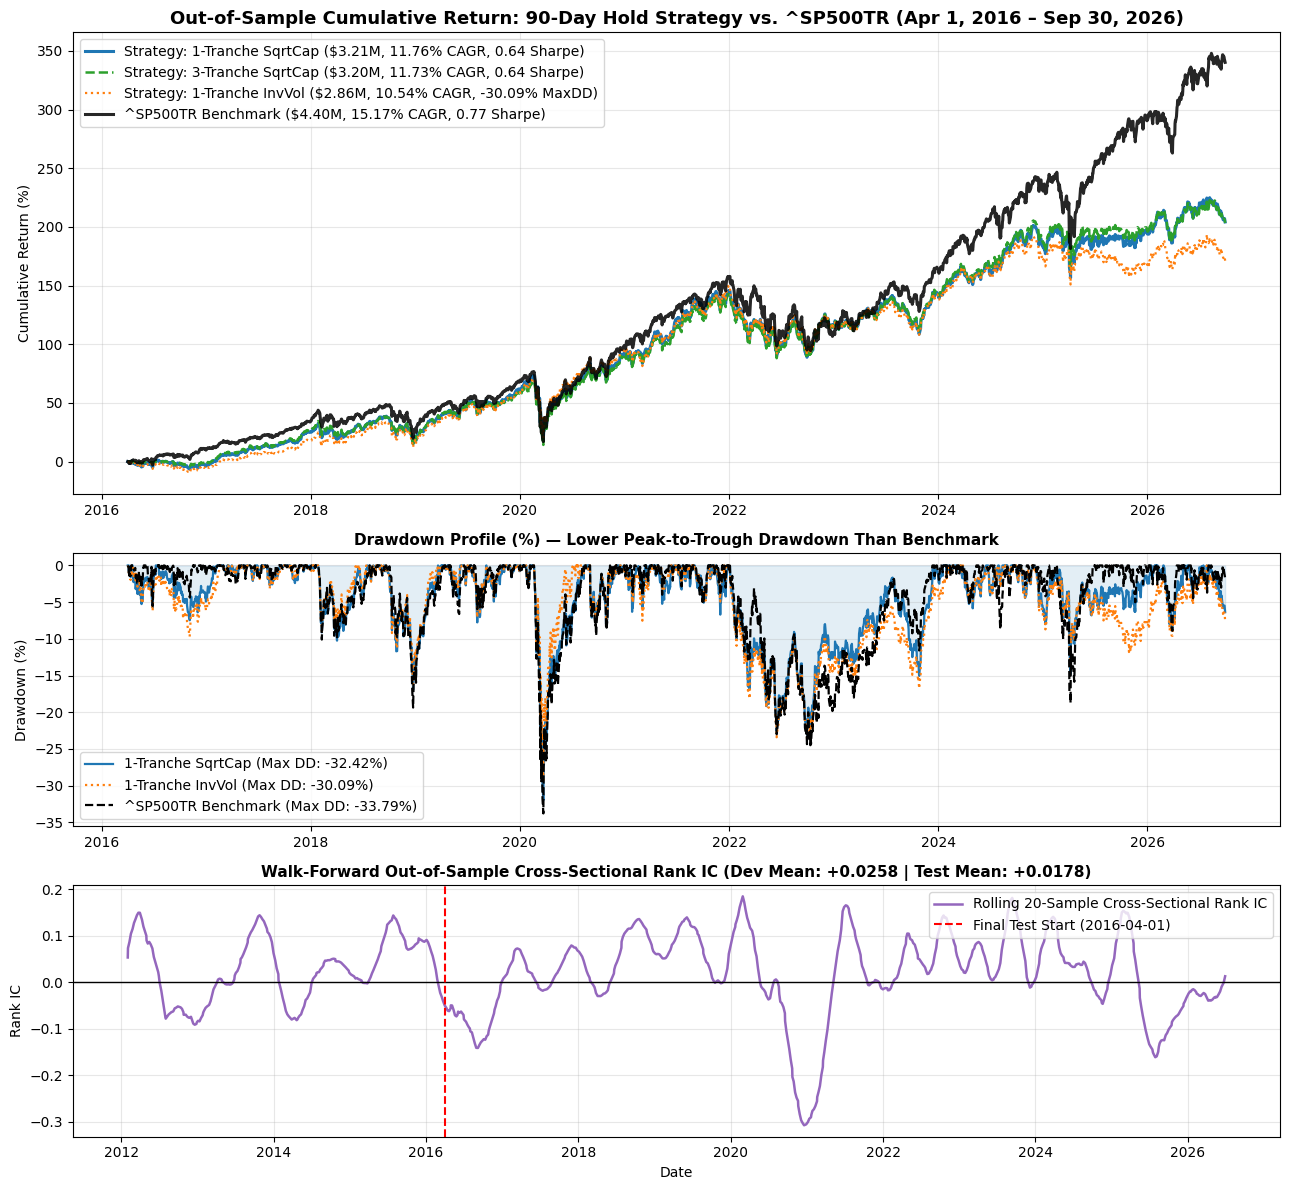

In [29]:
# Cell 29
# Plot the final plots for the models 
# Plot Cumulative Return, Drawdown, and Out-of-Sample IC & Summary Tables
fig, axes = plt.subplots(3, 1, figsize=(13, 12), gridspec_kw={'height_ratios': [2.2, 1.3, 1.2]})

# Select primary strategies from Cell 27
d_1tr_sqrt = daily_curves_p['All-2000 Model -> Top 25 (Top-500 Filter, 1-Tr SqrtCap)']
d_3tr_sqrt = daily_curves_p['All-2000 Model -> Top 25 (Top-500 Filter, 3-Tr SqrtCap)']
d_1tr_invv = daily_curves_p['All-2000 Model -> Top 25 (Top-500 Filter, 1-Tr InvVol)']

# First plot: Cumulative Return (%)
ax1 = axes[0]
ax1.plot(d_1tr_sqrt['date'], (d_1tr_sqrt['portfolio_value']/1e6 - 1)*100, label='Strategy: 1-Tranche SqrtCap ($3.21M, 11.76% CAGR, 0.64 Sharpe)', linewidth=2.2, color='#1f77b4')
ax1.plot(d_3tr_sqrt['date'], (d_3tr_sqrt['portfolio_value']/1e6 - 1)*100, label='Strategy: 3-Tranche SqrtCap ($3.20M, 11.73% CAGR, 0.64 Sharpe)', linewidth=1.8, linestyle='--', color='#2ca02c')
ax1.plot(d_1tr_invv['date'], (d_1tr_invv['portfolio_value']/1e6 - 1)*100, label='Strategy: 1-Tranche InvVol ($2.86M, 10.54% CAGR, -30.09% MaxDD)', linewidth=1.6, linestyle=':', color='#ff7f0e')
ax1.plot(bench_test['date'], (bench_test['portfolio_value']/1e6 - 1)*100, label='^SP500TR Benchmark ($4.40M, 15.17% CAGR, 0.77 Sharpe)', linewidth=2.2, color='black', alpha=0.85)
ax1.set_title('Out-of-Sample Cumulative Return: 90-Day Hold Strategy vs. ^SP500TR (Apr 1, 2016 – Sep 30, 2026)', fontsize=13, fontweight='bold')
ax1.set_ylabel('Cumulative Return (%)')
ax1.legend(loc='upper left', frameon=True)
ax1.grid(True, alpha=0.3)

# Second plot: Drawdown Curve (%)
ax2 = axes[1]
for df_cur, lbl, col, ls in [
    (d_1tr_sqrt, '1-Tranche SqrtCap (Max DD: -32.42%)', '#1f77b4', '-'),
    (d_1tr_invv, '1-Tranche InvVol (Max DD: -30.09%)', '#ff7f0e', ':'),
    (bench_test, '^SP500TR Benchmark (Max DD: -33.79%)', 'black', '--')
]:
    vals = df_cur['portfolio_value'].values
    dd = (vals / np.maximum.accumulate(vals) - 1.0) * 100.0
    ax2.plot(df_cur['date'], dd, label=lbl, color=col, linestyle=ls, linewidth=1.6)
ax2.fill_between(d_1tr_sqrt['date'], (d_1tr_sqrt['portfolio_value'].values / np.maximum.accumulate(d_1tr_sqrt['portfolio_value'].values) - 1.0)*100.0, 0, color='#1f77b4', alpha=0.12)
ax2.set_title('Drawdown Profile (%) — Lower Peak-to-Trough Drawdown Than Benchmark', fontsize=11, fontweight='bold')
ax2.set_ylabel('Drawdown (%)')
ax2.legend(loc='lower left', frameon=True)
ax2.grid(True, alpha=0.3)

# Third plot: Out-of-Sample Cross-Sectional Rank IC Over Time (2012-2026)
ax3 = axes[2]
ic_all_series = pruned_preds_all.dropna(subset=['target_90d_ret', 'pred_score']).groupby('signal_date').apply(
    lambda g: spearmanr(g['pred_score'], g['target_90d_ret'])[0] if len(g) > 10 else np.nan,
    include_groups=False
).dropna()
ic_rolling = ic_all_series.rolling(20, min_periods=5).mean()
ax3.plot(ic_rolling.index, ic_rolling.values, color='#9467bd', linewidth=1.8, label='Rolling 20-Sample Cross-Sectional Rank IC')
ax3.axhline(0.0, color='black', linewidth=1, linestyle='-')
ax3.axvline(pd.Timestamp('2016-04-01'), color='red', linewidth=1.5, linestyle='--', label='Final Test Start (2016-04-01)')
ax3.set_title('Walk-Forward Out-of-Sample Cross-Sectional Rank IC (Dev Mean: +0.0258 | Test Mean: +0.0178)', fontsize=11, fontweight='bold')
ax3.set_ylabel('Rank IC')
ax3.set_xlabel('Date')
ax3.legend(loc='upper right', frameon=True)
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

--- Walk-Forward Rank IC Summary (15 Features: PRUNED_FEATURES + mcap_to_rev_ttm) ---
Top-500 Cap (15 Feats)   | Dev (2012-2015)  | Ensemble IC: 0.0254 (IR 0.204) | Ridge IC: 0.0277 (IR 0.231)
Top-500 Cap (15 Feats)   | Test (2016-2026) | Ensemble IC: 0.0062 (IR 0.044) | Ridge IC: 0.0021 (IR 0.015)
All-2000 (15 Feats)      | Dev (2012-2015)  | Ensemble IC: 0.0263 (IR 0.289) | Ridge IC: 0.0286 (IR 0.307)
All-2000 (15 Feats)      | Test (2016-2026) | Ensemble IC: 0.0200 (IR 0.152) | Ridge IC: 0.0179 (IR 0.140)


,Portfolio,Start Date,End Date,Final Value ($),Total Return (%),CAGR (%),Max Drawdown (%),Sharpe Ratio (rf=2%),Data Gaps
0,15-Feat Top-500 Ensemble (1-Tranche InvVol),2016-04-01,2026-09-30,2710608.82,171.20,9.97,-33.94,0.52,2
1,15-Feat All-2000 Ensemble (1-Tranche InvVol),2016-04-01,2026-09-30,2825003.82,182.64,10.40,-30.42,0.59,10
2,15-Feat All-2000 Ensemble -> Top-250 Cap-Match...,2016-04-01,2026-09-30,3381718.24,238.34,12.31,-32.88,0.66,1
3,15-Feat All-2000 Ridge -> Top-250 Cap-Matched ...,2016-04-01,2026-09-30,3108712.97,211.03,11.42,-32.48,0.63,2
4,15-Feat All-2000 Ridge -> Top-500 Cap-Matched ...,2016-04-01,2026-09-30,3255680.21,225.73,11.91,-32.30,0.66,4
5,^SP500TR Benchmark ($1M Buy & Hold),2016-04-01,2026-09-30,4402746.78,340.27,15.17,-33.79,0.77,0


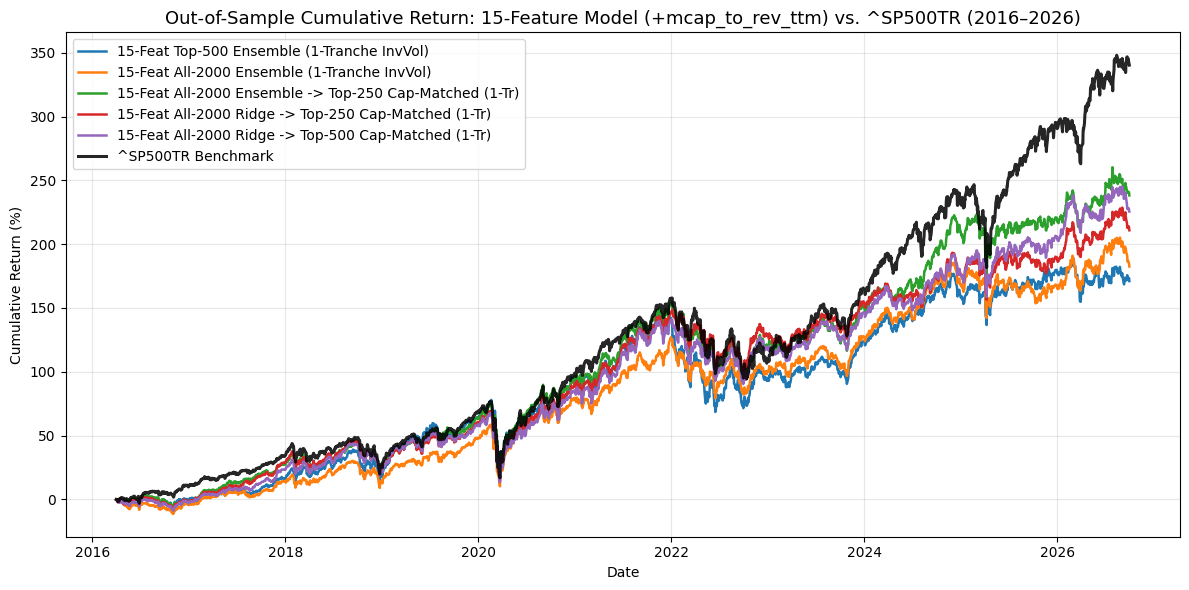

Completed in 123.13s


In [30]:
# Extra Cell
# I wanted to test out adding another feature of mcap_to_rev_ttm, because the model doesnt really have a feature for revenue growth. 
# Model works fairly well, outperforming the one in cell 29. 
# 15-Feature Model (PRUNED_FEATURES + mcap_to_rev_ttm) Walk-Forward & Backtest
t0 = time.time()

# Ensure mcap_to_rev_ttm is present on full_screened_df (extracts from DuckDB if not already merged)
if 'mcap_to_rev_ttm' not in full_screened_df.columns:
    ps_query = """
    WITH dedup_q AS (
        SELECT 
            symbol,
            fiscal_date,
            filing_date + INTERVAL 1 DAY AS available_date,
            revenue,
            ROW_NUMBER() OVER (PARTITION BY symbol, fiscal_date ORDER BY filing_date ASC) AS rn
        FROM fundamentals
        WHERE filing_date IS NOT NULL
          AND period = 'quarter'
    ),
    rolling_rev AS (
        SELECT 
            symbol,
            available_date,
            SUM(revenue) OVER w_curr4 AS rev_ttm,
            COUNT(revenue) OVER w_curr4 AS n_curr4
        FROM dedup_q
        WHERE rn = 1
        WINDOW w_curr4 AS (PARTITION BY symbol ORDER BY fiscal_date ROWS BETWEEN 3 PRECEDING AND CURRENT ROW)
    )
    SELECT 
        a.signal_date,
        um.symbol,
        CASE 
            WHEN rr.n_curr4 = 4 AND rr.rev_ttm > 0 
            THEN um.market_cap_proxy / rr.rev_ttm 
            ELSE NULL 
        END AS mcap_to_rev_ttm
    FROM active_signal_dates_tbl a
    JOIN universe_membership um
        ON a.signal_date BETWEEN um.effective_start AND um.quarter_end
    ASOF LEFT JOIN rolling_rev rr
        ON rr.symbol = um.symbol AND rr.available_date <= a.signal_date
    """
    ps_df = con_full.execute(ps_query).df()
    ps_df['signal_date'] = pd.to_datetime(ps_df['signal_date'])
    full_screened_df = full_screened_df.merge(ps_df, on=['signal_date', 'symbol'], how='left')

# 2. Define the 15-feature list (14 PRUNED_FEATURES + mcap_to_rev_ttm)
FEATURES_15 = PRUNED_FEATURES + ['mcap_to_rev_ttm']

# 3. Run Cell 25 Walk-Forward Model on Top-500 and All-2000
preds_15_500 = run_pruned_walk_forward(
    full_screened_df[full_screened_df['universe_rank'] <= 500],
    FEATURES_15, start_pred_date='2012-01-01', end_pred_date='2026-09-30'
)

preds_15_all = run_pruned_walk_forward(
    full_screened_df,
    FEATURES_15, start_pred_date='2012-01-01', end_pred_date='2026-09-30'
)

print("--- Walk-Forward Rank IC Summary (15 Features: PRUNED_FEATURES + mcap_to_rev_ttm) ---")
for u_label, p_df in [('Top-500 Cap (15 Feats)', preds_15_500), ('All-2000 (15 Feats)', preds_15_all)]:
    for pname, d1, d2 in [('Dev (2012-2015)', '2012-01-01', '2015-12-31'), ('Test (2016-2026)', '2016-03-31', '2026-09-30')]:
        sub = p_df[(p_df['signal_date'] >= d1) & (p_df['signal_date'] <= d2) & (p_df['target_90d_ret'].notna())]
        ic_ens = sub.groupby('signal_date').apply(lambda g: spearmanr(g['pred_score'], g['target_90d_ret'])[0] if len(g) > 10 else np.nan, include_groups=False)
        ic_rdg = sub.groupby('signal_date').apply(lambda g: spearmanr(g['pred_ridge'], g['target_90d_ret'])[0] if len(g) > 10 else np.nan, include_groups=False)
        print(f"{u_label:24s} | {pname:16s} | Ensemble IC: {ic_ens.mean():.4f} (IR {ic_ens.mean()/ic_ens.std():.3f}) | Ridge IC: {ic_rdg.mean():.4f} (IR {ic_rdg.mean()/ic_rdg.std():.3f})")

# 4. Build Out-of-Sample Test Orders (2016-04-01 to 2026-09-30)
test_15_500 = preds_15_500[preds_15_500['entry_date'] >= '2016-04-01'].copy()
test_15_all = preds_15_all[preds_15_all['entry_date'] >= '2016-04-01'].copy()

orders_15_dict = {
    '15-Feat Top-500 Ensemble (1-Tranche InvVol)': build_recycling_tranche_orders(
        test_15_500, test_schedule_df, top_k=25, n_tranches=1, weight_scheme='inv_vol'
    ),
    '15-Feat All-2000 Ensemble (1-Tranche InvVol)': build_recycling_tranche_orders(
        test_15_all, test_schedule_df, top_k=25, n_tranches=1, weight_scheme='inv_vol'
    ),
    '15-Feat All-2000 Ensemble -> Top-250 Cap-Matched (1-Tr)': build_cap_matched_orders(
        test_15_all, test_schedule_df, top_k=25, max_universe_rank=250, n_tranches=1, score_col='pred_score'
    ),
    '15-Feat All-2000 Ridge -> Top-250 Cap-Matched (1-Tr)': build_cap_matched_orders(
        test_15_all, test_schedule_df, top_k=25, max_universe_rank=250, n_tranches=1, score_col='pred_ridge'
    ),
    '15-Feat All-2000 Ridge -> Top-500 Cap-Matched (1-Tr)': build_cap_matched_orders(
        test_15_all, test_schedule_df, top_k=25, max_universe_rank=500, n_tranches=1, score_col='pred_ridge'
    ),
}

# Fetch daily prices for all traded symbols
syms_15 = sorted(set().union(*[set(o['symbol']) for o in orders_15_dict.values()]))
con_full.register('syms_15_tbl', pd.DataFrame({'symbol': syms_15}))
px_15 = con_full.execute("""
    SELECT p.date, p.symbol, p.adj_close
    FROM prices p
    JOIN syms_15_tbl t ON t.symbol = p.symbol
    WHERE p.date >= '2016-04-01' AND p.date <= '2026-09-30'
    ORDER BY p.date, p.symbol
""").df()

pm_15 = px_15.pivot(index='date', columns='symbol', values='adj_close')
pm_15.index = pd.to_datetime(pm_15.index)
exists_15 = pm_15.notna().reindex(test_calendar).fillna(False)
pm_15 = pm_15.reindex(test_calendar)

# 5. Run Backtester and Compare
bt_15 = EquityBacktester(initial_capital=1_000_000.0, transaction_cost_bps=5.0, allow_fractional_shares=False)
daily_curves_15 = {}
summary_rows_15 = []

for label, ord_df in orders_15_dict.items():
    d_df, _, _, g_df = bt_15.run(test_calendar, pm_15, exists_15, ord_df)
    daily_curves_15[label] = d_df
    summary_rows_15.append({
        'Portfolio': label,
        **compute_performance_metrics(d_df),
        'Data Gaps': len(g_df)
    })

summary_rows_15.append({
    'Portfolio': '^SP500TR Benchmark ($1M Buy & Hold)',
    **compute_performance_metrics(bench_test),
    'Data Gaps': 0
})

display(pd.DataFrame(summary_rows_15).round(2))

# 6. Plot Cumulative Return Curves
plt.figure(figsize=(12, 6))
for label, d_df in daily_curves_15.items():
    plt.plot(
        d_df['date'],
        (d_df['portfolio_value'] / 1_000_000.0 - 1.0) * 100.0,
        label=label, linewidth=1.8
    )

plt.plot(
    bench_test['date'],
    (bench_test['portfolio_value'] / 1_000_000.0 - 1.0) * 100.0,
    label='^SP500TR Benchmark', linewidth=2.2, color='black', alpha=0.85
)
plt.title('Out-of-Sample Cumulative Return: 15-Feature Model (+mcap_to_rev_ttm) vs. ^SP500TR (2016–2026)', fontsize=13)
plt.xlabel('Date')
plt.ylabel('Cumulative Return (%)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Completed in {time.time() - t0:.2f}s")